# DAS732 A3: Visual Analytics Workflow on World Energy Consumption

**Research question:** How are the world's countries moving through the energy transition, and does getting richer still mean using more energy and running a dirtier electricity grid?

**Framework:** the Keim et al. (2008) visual analytics diamond (Data → Visualization ⇄ Models → Knowledge), run twice, with a feedback loop between the iterations that significantly transforms the data.

**How this notebook is organised:** all logic lives in `src/`; this notebook only calls it, explains each decision, and prints the key numbers. Every figure is saved to `images/` and every number to `results/`.

| Phase | Diamond stage |
|---|---|
| 1. Data preparation | Data |
| 2. Iteration 1: snapshot analysis on raw scales | Visualization → Models → Knowledge |
| 3. Feedback loop: significant transformation | Knowledge → Data |
| 4. Iteration 2: transition archetypes | Visualization → Models → Knowledge |
| 5. Workflow diagram | (summary) |

## Setup

In [1]:
# Cell 1: make the project root importable (the notebook lives in notebooks/).
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline

In [2]:
# Cell 2: imports and shared figure style.
import numpy as np
import pandas as pd

from src import config
from src.plots import apply_style

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
print("Project root:", ROOT)
print("Raw data present:", config.RAW_CSV.exists())

Project root: <project root>
Raw data present: True


## Phase 1: Data preparation (Data)

### 1.1 Load and validate the raw file
`load_raw()` asserts the expected shape, year range and entity count, so a wrong or
modified file fails immediately instead of silently producing different results.

In [3]:
from src import figures, logbook, plots, prep

raw = prep.load_raw()
print(
    f"Raw file: {raw.shape[0]:,} rows x {raw.shape[1]} columns, "
    f"years {raw['year'].min()}-{raw['year'].max()}, {raw['country'].nunique()} entities"
)

Raw file: 22,012 rows x 129 columns, years 1900-2022, 306 entities


### 1.2 Keep real countries only
OWID mixes countries with aggregates (World, continents, income groups, and source-specific
groupings such as "(EI)", "(EIA)", "(Ember)", "(Shift)"). Aggregates have no ISO code, and
keeping them would count the same energy twice. Kosovo is a real country but has no ISO
code in this file, so it is dropped as well and listed separately.

In [4]:
countries, dropped = prep.drop_aggregates(raw)
dropped.to_csv(config.RESULTS / "dropped_entities.csv", index=False)
print(f"Countries kept: {countries['country'].nunique()} | entities dropped: {len(dropped)}")
print(dropped["reason"].value_counts().to_string())

Countries kept: 219 | entities dropped: 87
reason
aggregate (no ISO code)          86
real country without ISO code     1


### 1.3 Analysis window and core columns
The electricity-mix columns start in 2000 for ~205 countries. 2022 covers only about half
the countries, so the window is 2000–2021. Only the core columns used later are kept.

In [5]:
panel = prep.filter_years(countries)
print(
    f"Rows: {len(countries):,} -> {len(panel):,} | columns: {countries.shape[1]} -> "
    f"{panel.shape[1]} | years {panel['year'].min()}-{panel['year'].max()}"
)

Rows: 16,512 -> 4,798 | columns: 129 -> 32 | years 2000-2021


### 1.4 Missingness: where are the holes?
Before deciding how to handle missing values, we look at *where* they are. The heatmap
shows two structural breaks the whole analysis is designed around: GDP ends after 2018,
and from 2017 the fossil-production columns list only the main producers.

In [6]:
missing_cols = prep.interpolation_columns() + config.RAW_PRODUCER_COLS
pct_missing = prep.missingness_by_year(panel, missing_cols)
pct_missing.to_csv(config.RESULTS / "missingness_by_year.csv")

fig = figures.missingness_heatmap(pct_missing)
plots.save_figure(
    fig,
    "iter1_missingness_heatmap.png",
    phase="Phase 1",
    what_it_shows=(
        "Percent of the 219 countries and territories missing each core column in each "
        "year 2000-2021, marking the 2017 producer-data break and the end of GDP after 2018."
    ),
    why_this_chart=(
        "A column-by-year heatmap shows the structure of missingness (whole blocks versus "
        "scattered cells) for every variable at once, which a table of ~400 numbers cannot."
    ),
)
pct_missing.loc[["gdp", "carbon_intensity_elec", "oil_prod_per_capita"], [2016, 2017, 2018, 2019]]

year,2016,2017,2018,2019
gdp,24.7,24.7,24.7,100.0
carbon_intensity_elec,6.4,6.4,6.4,6.4
oil_prod_per_capita,1.4,77.6,77.6,77.6


### 1.5 Fossil-producer features (avoiding the 2017 break)
Up to 2016 the source records non-producers as an explicit 0. From 2017 it lists only the
main producers and leaves everyone else blank, including real producers. Filling those
blanks with 0 would mislabel real producers, so producer features use **only data up to
2016**: the 2016 value and the 2000–2016 mean.

In [7]:
producers, lost_2017 = prep.producer_features(panel)
producers.to_csv(config.DATA_PROCESSED / "producers.csv", index=False)
logbook.save_metrics("producers_lost_2017", lost_2017)
print("Countries producing in 2016 but blank in 2017:", lost_2017)
print(f"Producer features available for {producers.dropna().shape[0]} countries")

Countries producing in 2016 but blank in 2017: {'oil': 50, 'gas': 46, 'coal': 31}
Producer features available for 216 countries


### 1.6 Interpolation: only inside a country, only short internal gaps
The rule: fill a gap linearly only if the **whole** gap is at most 3 years and has data on
both sides, one country at a time. Never extrapolate and never borrow from another country.

First we classify every missing cell by where it sits in its country's series. Only
internal gaps can be filled without extrapolating.

In [8]:
interp_cols = prep.interpolation_columns()
missing_kinds = prep.classify_missing(panel, interp_cols)
missing_kinds.to_csv(config.RESULTS / "missing_cell_types.csv", index=False)
print(missing_kinds.drop(columns="column").sum().to_string())

panel, filled = prep.interpolate_within_country(panel, interp_cols)
interpolation_log = missing_kinds.set_index("column").assign(
    cells_filled=filled, missing_after=prep.count_missing(panel, interp_cols)
)
interpolation_log.to_csv(config.RESULTS / "interpolation_log.csv")
print(f"\nCells filled by interpolation: {int(filled.sum())}")

country_never_reports    6218
leading_edge               66
trailing_edge            1791
internal_gap                0



Cells filled by interpolation: 0


**Finding:** inside 2000–2021 the OWID series have **no internal gaps**. Every missing cell
is structural: the country never reports the column, or its series starts late or ends
early (mostly GDP after 2018). Interpolation therefore fills nothing, and filling more
would mean extrapolating. Structural missingness is handled instead by the coverage rule
(1.7) and by the analysis windows (GDP-based work stops at 2018).

### 1.7 Derived per-person columns
`gdp_pc` = GDP / population (international-$ per person, PPP).
`ghg_pc` = electricity-sector emissions x 10^6 / population (tonnes CO2e per person).

In [9]:
panel = prep.add_derived(panel)
panel[["gdp_pc", "ghg_pc"]].describe().round(2)

,gdp_pc,ghg_pc
count,3130.00,4688.00
mean,15899.64,1.45
std,17717.64,1.87
min,438.61,0.00
25%,3281.17,0.11
50%,9847.77,0.73
75%,22738.55,2.17
max,166150.49,10.63


### 1.8 Make the electricity mix a proper composition
The 8 mix shares should be complete and sum to 100. Two problems were found:

1. **Structural zeros.** Some countries leave a share blank instead of writing 0 (mostly
   nuclear: Chile, Indonesia, Malaysia, Saudi Arabia, …). When the other shares already
   cover the whole grid *and* that source's TWh is also blank, the source is not used, so
   both its share and its TWh are set to 0. Without this, those countries would drop out of
   every analysis that needs all 8 sources, including the balanced panel for world totals.
2. **Inconsistent totals.** In Chile the per-source TWh add up to more than total
   generation, so its shares sum to up to ~112%. Rows off by more than 0.5 pp are rescaled
   to 100. CLR (Phase 3) uses only ratios between shares, which rescaling does not change.

`low_carbon_share_elec` is then recomputed from the closed shares. Carbon intensity is never
modified.

In [10]:
panel, mix_closure = prep.close_mix_shares(panel)
mix_closure.to_csv(config.RESULTS / "mix_closure_log.csv", index=False)
mix_closure.round(2)

,country,zero_filled_cells,renormalised_rows,max_sum_before,max_low_carbon_change_pp
0,Chile,22,22,111.66,6.47
1,Indonesia,22,0,NaN,0.00
2,Iran,11,0,NaN,0.00
3,Kazakhstan,22,0,NaN,0.01
4,Malaysia,22,0,NaN,0.29
5,Saudi Arabia,44,0,NaN,0.00
6,Vietnam,10,0,NaN,0.01


### 1.9 Coverage rule
A country missing more than 30% of its core electricity cells (8 shares, low-carbon share,
carbon intensity, generation) cannot be placed reliably in any chart or model, so it is
dropped. This also removes the ISO-coded entities with no grid data at all (Antarctica,
Netherlands Antilles, …).

In [11]:
rows_before, countries_before = len(panel), panel["country"].nunique()
panel, dropped_coverage = prep.apply_coverage_rule(panel)
dropped_coverage.to_csv(config.RESULTS / "dropped_low_coverage.csv", index=False)
print(
    f"Dropped {len(dropped_coverage)} countries: {countries_before} -> "
    f"{panel['country'].nunique()} countries, {rows_before:,} -> {len(panel):,} rows"
)
dropped_coverage

Dropped 14 countries: 219 -> 205 countries, 4,798 -> 4,490 rows


,country,missing_share
0,French Guiana,0.413
1,Guadeloupe,0.413
2,Martinique,0.413
3,Reunion,0.413
4,Western Sahara,0.496
5,Saint Helena,0.909
6,Gibraltar,0.909
7,Bermuda,0.909
8,Niue,0.909
9,Netherlands Antilles,1.000


### 1.10 Sanity checks
`sanity_checks()` raises an error if any rule is broken: duplicate country-years, negative
values, mix rows not summing to 100 (±0.5), or a low-carbon share that disagrees with its
five parts.

In [12]:
checks = prep.sanity_checks(panel)
logbook.save_metrics("sanity_checks", checks)
pd.Series(checks).to_frame("value")

,value
rows,4490.000
countries,205.000
duplicate_country_years,0.000
negative_cells,0.000
complete_mix_rows,4489.000
mix_sum_min,99.713
mix_sum_max,100.412
mix_rows_outside_tolerance,0.000
low_carbon_max_gap_pp,0.000


### 1.11 Balanced panel for world totals
Summing countries whose coverage changes from year to year creates artificial jumps. World
totals and global trends therefore use only countries with generation and all 8 shares in
every year 2000–2021.

In [13]:
balanced = prep.balanced_countries(panel)
pd.Series(balanced, name="country").to_csv(
    config.DATA_PROCESSED / "balanced_countries.csv", index=False
)
print(f"Balanced panel: {len(balanced)} of {panel['country'].nunique()} countries")

Balanced panel: 201 of 205 countries


### 1.12 OWID's own World row (validation only)
The aggregate "World" row was dropped in 1.2. A copy of its TWh by source is kept only to
check our country sums in Phase 2. It is never used in the analysis.

In [14]:
world_check = prep.world_check_rows(raw)
world_check.to_csv(config.DATA_PROCESSED / "world_check.csv", index=False)
first_year, last_year = world_check["year"].min(), world_check["year"].max()
print(f"World rows saved: {len(world_check)} ({first_year}-{last_year})")

World rows saved: 22 (2000-2021)


### 1.13 Save the clean panel and the data dictionary
The raw producer columns are **removed** from the clean panel: after 2016 they are unusable,
and dropping them makes accidental use impossible. Producer information lives only in
`producers.csv` (pre-2017 data).

In [15]:
panel_clean = panel.drop(columns=config.RAW_PRODUCER_COLS)
panel_clean.to_csv(config.DATA_PROCESSED / "panel_clean.csv", index=False)
dictionary = prep.data_dictionary(
    list(panel_clean.columns) + [c for c in producers.columns if c != "country"]
)
dictionary.to_csv(config.RESULTS / "data_dictionary.csv", index=False)
print(f"panel_clean.csv: {panel_clean.shape[0]:,} rows x {panel_clean.shape[1]} columns")
dictionary.head(8)

panel_clean.csv: 4,490 rows x 31 columns


,column,description,unit,origin
0,country,Country or territory name,-,raw OWID
1,iso_code,ISO 3166-1 alpha-3 code,-,raw OWID
2,year,Calendar year,year,raw OWID
3,population,Population,people,raw OWID
4,gdp,"Gross domestic product (PPP, ends 2018)",international-$,raw OWID
5,greenhouse_gas_emissions,Greenhouse-gas emissions from electricity gene...,MtCO2e,raw OWID
6,energy_per_capita,Primary energy consumption per person,kWh per person,raw OWID
7,per_capita_electricity,Electricity generation per person,kWh per person,raw OWID


### 1.14 The 2018 snapshot used by iteration 1
2018 is the last year with GDP. The snapshot joins the 2016 producer features. We record
how many countries have complete data for each feature set used later.

In [16]:
snapshot = panel_clean[panel_clean["year"] == config.SNAPSHOT_YEAR].merge(
    producers, on="country", how="left", validate="one_to_one"
)
snapshot.to_csv(config.DATA_PROCESSED / "snapshot_2018.csv", index=False)

feature_sets = {
    "kmeans_iter1": config.MIX_SHARE_COLS
    + ["energy_per_capita", "per_capita_electricity", config.TARGET_COL],
    "rf_iter1": ["gdp_pc", "energy_per_capita", "per_capita_electricity", "population"]
    + [f"{fuel}_prod_pc_2016" for fuel in ("oil", "gas", "coal")]
    + [config.TARGET_COL],
    "gdp_vs_energy": ["gdp_pc", "energy_per_capita"],
}
set_sizes = {
    name: int(snapshot[cols].notna().all(axis=1).sum()) for name, cols in feature_sets.items()
}
logbook.save_metrics("snapshot_feature_set_sizes", set_sizes)
print(f"Snapshot {config.SNAPSHOT_YEAR}: {len(snapshot)} countries")
print("Countries with complete data per feature set:", set_sizes)

Snapshot 2018: 205 countries
Countries with complete data per feature set: {'kmeans_iter1': 205, 'rf_iter1': 165, 'gdp_vs_energy': 165}


### 1.15 Phase 1 summary

In [17]:
phase1_summary = pd.DataFrame(
    [
        ("Raw file", len(raw), raw["country"].nunique(), "1900-2022"),
        ("Countries only (ISO code)", len(countries), countries["country"].nunique(), "1900-2022"),
        ("Window 2000-2021 + core columns", rows_before, countries_before, "2000-2021"),
        (
            "After coverage rule (clean panel)",
            len(panel_clean),
            panel_clean["country"].nunique(),
            "2000-2021",
        ),
        (
            "Balanced panel (world totals)",
            len(panel_clean[panel_clean["country"].isin(balanced)]),
            len(balanced),
            "2000-2021",
        ),
        ("Snapshot 2018", len(snapshot), snapshot["country"].nunique(), "2018"),
    ],
    columns=["stage", "rows", "countries", "years"],
)
phase1_summary.to_csv(config.RESULTS / "phase1_summary.csv", index=False)
phase1_summary

,stage,rows,countries,years
0,Raw file,22012,306,1900-2022
1,Countries only (ISO code),16512,219,1900-2022
2,Window 2000-2021 + core columns,4798,219,2000-2021
3,After coverage rule (clean panel),4490,205,2000-2021
4,Balanced panel (world totals),4422,201,2000-2021
5,Snapshot 2018,205,205,2018


In [18]:
notes = [
    f"{len(dropped)} entities without an ISO code were dropped (aggregates, plus Kosovo, a "
    "real country without an ISO code in this file).",
    f"Analysis window {config.YEAR_START}-{config.YEAR_END}: 2022 covers only about half the "
    "countries.",
    f"GDP and energy_per_gdp end in {config.GDP_LAST_YEAR}; GDP-based analysis stops there.",
    f"Producer columns list only main producers from {config.PRODUCER_LAST_FULL_YEAR + 1}; "
    f"countries producing in {config.PRODUCER_LAST_FULL_YEAR} but blank the next year: "
    f"{lost_2017}. Producer features therefore use data up to "
    f"{config.PRODUCER_LAST_FULL_YEAR} only, and the raw producer columns are removed.",
    f"Missing cells in the core columns: {int(missing_kinds['internal_gap'].sum())} internal "
    f"gaps, so interpolation filled {int(filled.sum())} cells. All missingness is structural.",
    f"Mix closure: {int(mix_closure['zero_filled_cells'].sum())} structural-zero cells filled "
    f"in {len(mix_closure)} countries; {int(mix_closure['renormalised_rows'].sum())} rows "
    "rescaled to 100 (Chile only).",
    f"Coverage rule dropped {len(dropped_coverage)} countries with >30% missing grid data, "
    f"leaving {panel_clean['country'].nunique()} countries.",
    f"Balanced panel for world totals: {len(balanced)} countries.",
]
logbook.write_notes("data_notes", "Phase 1 data notes", notes)
print("\n".join(notes))

87 entities without an ISO code were dropped (aggregates, plus Kosovo, a real country without an ISO code in this file).
Analysis window 2000-2021: 2022 covers only about half the countries.
GDP and energy_per_gdp end in 2018; GDP-based analysis stops there.
Producer columns list only main producers from 2017; countries producing in 2016 but blank the next year: {'oil': 50, 'gas': 46, 'coal': 31}. Producer features therefore use data up to 2016 only, and the raw producer columns are removed.
Missing cells in the core columns: 0 internal gaps, so interpolation filled 0 cells. All missingness is structural.
Mix closure: 153 structural-zero cells filled in 7 countries; 22 rows rescaled to 100 (Chile only).
Coverage rule dropped 14 countries with >30% missing grid data, leaving 205 countries.
Balanced panel for world totals: 201 countries.


## Phase 2: Iteration 1: snapshot analysis on raw scales

Iteration 1 deliberately uses the data **as it comes**: raw scales, one snapshot year (2018),
shares treated as ordinary numbers. Its job is to find out what is wrong with that view; the
problems it reveals trigger the feedback loop in Phase 3.

In [19]:
from src import features

panel_clean = pd.read_csv(config.DATA_PROCESSED / "panel_clean.csv")
snapshot = pd.read_csv(config.DATA_PROCESSED / "snapshot_2018.csv")
balanced = pd.read_csv(config.DATA_PROCESSED / "balanced_countries.csv")["country"].tolist()
world_check = pd.read_csv(config.DATA_PROCESSED / "world_check.csv")
print(f"Clean panel: {panel_clean['country'].nunique()} countries | snapshot: {len(snapshot)}")

Clean panel: 205 countries | snapshot: 205


### 2.1 The global picture: world electricity generation by source
World totals are summed over the **balanced panel** (the same countries every year), so the
trend is not distorted by countries entering or leaving the data. OWID's own "World" row is
used only to check how much of world generation these countries cover.

In [20]:
global_twh = features.global_mix_twh(panel_clean, balanced)
global_low_carbon = features.low_carbon_share_of_total(global_twh)
global_twh.assign(low_carbon_share_pct=global_low_carbon).round(2).to_csv(
    config.RESULTS / "global_mix_twh.csv"
)
coverage = features.world_coverage_check(global_twh, world_check)
coverage.to_csv(config.RESULTS / "global_mix_check.csv")
print(
    f"Balanced panel covers {coverage['coverage_pct'].min():.2f}-"
    f"{coverage['coverage_pct'].max():.2f}% of OWID world generation (all years); "
    f"per source {coverage['min_source_coverage_pct'].min():.1f}-"
    f"{coverage['max_source_coverage_pct'].max():.1f}%"
)

fig = figures.global_mix_area(global_twh, global_low_carbon, len(balanced))
plots.save_figure(
    fig,
    "iter1_global_mix_area.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "World electricity generation by source 2000-2021, summed over a fixed panel of "
        "countries, with the fossil/low-carbon boundary and the low-carbon share."
    ),
    why_this_chart=(
        "A stacked area shows both the total and each source's contribution over time, so "
        "growth in total demand and the shift between sources are visible in one view."
    ),
    inference_id="I1-3",
)
global_low_carbon.round(1).iloc[[0, int(global_low_carbon.argmin()), -1]].rename(
    "low-carbon share (%)"
)

Balanced panel covers 99.93-99.99% of OWID world generation (all years); per source 99.6-101.5%


year
2000    35.8
2007    32.0
2021    38.2
Name: low-carbon share (%), dtype: float64

### 2.2 Distributions on raw scales
Before modelling, we check the shape of the key variables across countries in 2018.

In [21]:
dist_cols = ["energy_per_capita", "gdp_pc", "carbon_intensity_elec", "per_capita_electricity"]
skewness = snapshot[dist_cols].skew().round(3).to_dict()
logbook.save_metrics("iter1_skew", skewness)

fig = figures.distributions(snapshot, dist_cols, skewness)
plots.save_figure(
    fig,
    "iter1_distributions.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Histograms of energy, GDP and electricity per person and grid carbon intensity "
        "across countries in 2018, on raw scales, with median and skewness."
    ),
    why_this_chart=(
        "Histograms show the shape of each distribution (skew, long tails, outliers), which "
        "decides whether raw scales are suitable for distance-based models and OLS."
    ),
    inference_id="I1-1",
)
pd.Series(skewness, name="skewness")

energy_per_capita         2.414
gdp_pc                    2.381
carbon_intensity_elec    -0.342
per_capita_electricity    4.832
Name: skewness, dtype: float64

### 2.3 GDP vs energy use on linear axes
The obvious first chart for "does getting richer mean using more energy?". Bubble area is
proportional to population.

In [22]:
fig = figures.gdp_vs_energy_linear(snapshot)
plots.save_figure(
    fig,
    "iter1_gdp_vs_energy_linear.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "GDP per person vs primary energy per person in 2018 on linear axes, bubble area = "
        "population; top-10 energy users and the 3 most populous countries labelled."
    ),
    why_this_chart=(
        "A scatter is the standard view of a relationship between two quantities; bubble "
        "size adds population, so the reader sees that the axes are set by a few small "
        "states while most people live in the crowded bottom-left corner."
    ),
    inference_id="I1-1",
)
top_energy = snapshot.nlargest(5, "energy_per_capita")
top_energy[["country", "energy_per_capita", "gdp_pc", "population"]].round(0)

,country,energy_per_capita,gdp_pc,population
150,Qatar,202570.0,144809.0,2766743.0
86,Iceland,188294.0,43392.0,352951.0
165,Singapore,163527.0,70537.0,5814543.0
13,Bahrain,142292.0,42061.0,1487346.0
193,United Arab Emirates,132789.0,80404.0,9140172.0


### 2.4 Pearson vs Spearman correlation
Pearson measures *linear* association and is sensitive to outliers; Spearman uses ranks and
captures any monotonic relationship. Where the two disagree strongly, the relationship is
non-linear or driven by outliers. Both use the same countries (complete on all 7 variables).

In [23]:
corr_cols = [
    "gdp_pc",
    "energy_per_capita",
    "per_capita_electricity",
    "energy_per_gdp",
    "carbon_intensity_elec",
    "low_carbon_share_elec",
    "ghg_pc",
]
corr_data = snapshot[corr_cols].dropna()
pearson = corr_data.corr(method="pearson")
spearman = corr_data.corr(method="spearman")
pearson.round(3).to_csv(config.RESULTS / "iter1_corr_pearson.csv")
spearman.round(3).to_csv(config.RESULTS / "iter1_corr_spearman.csv")

fig = figures.correlation_pair(pearson, spearman, len(corr_data))
plots.save_figure(
    fig,
    "iter1_corr_pearson_vs_spearman.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Pearson and Spearman correlation matrices of 7 key variables in 2018 (same "
        "countries), with cells where the two differ by at least 0.2 outlined."
    ),
    why_this_chart=(
        "Side-by-side annotated heatmaps make the two coefficient matrices directly "
        "comparable cell by cell; outlining large gaps points to non-linearity and outliers."
    ),
    inference_id="I1-1",
)
gap = (spearman - pearson).abs()
largest_gaps = gap.where(np.triu(np.ones(gap.shape, dtype=bool), k=1)).stack().nlargest(3)
largest_gaps.round(2).rename("|rho - r|")

per_capita_electricity  ghg_pc                    0.34
gdp_pc                  per_capita_electricity    0.25
                        energy_per_gdp            0.20
Name: |rho - r|, dtype: float64

### 2.5 Where is electricity low-carbon? (spatial view)

In [24]:
lc_map = plots.choropleth(
    snapshot,
    "low_carbon_share_elec",
    title=f"Low-carbon share of electricity generation, {config.SNAPSHOT_YEAR} "
    f"({snapshot['low_carbon_share_elec'].notna().sum()} countries)",
    colorbar_title="Low-carbon share of electricity (%)",
    range_color=(0, 100),
)
plots.save_plotly_figure(
    lc_map,
    "iter1_lowcarbon_choropleth_2018.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Share of each country's electricity from nuclear and renewables in 2018, on a "
        "fixed 0-100% scale; excluded countries in grey."
    ),
    why_this_chart=(
        "A choropleth shows the spatial pattern of the energy transition (regional "
        "clusters such as hydro-rich South America and fossil-based Middle East) that a "
        "table or bar chart would hide."
    ),
    inference_id="I1-3",  # the single-year level that I1-3 shows hides each country's path
)
snapshot.nlargest(5, "low_carbon_share_elec")[["country", "low_carbon_share_elec"]]

,country,low_carbon_share_elec
1,Albania,100.0
20,Bhutan,100.0
35,Central African Republic,100.0
86,Iceland,100.0
105,Lesotho,100.0


### 2.6 What does a single snapshot hide?
Iteration 1 is built on one year (2018). To test whether that is enough, we compare each
country's low-carbon share at two 3-year endpoints (2000–02 and 2016–18). If countries kept
their positions, a snapshot would be a fair summary; if they moved a lot, it is not.

In [25]:
from src import stats

change_table = features.endpoint_change(panel_clean, "low_carbon_share_elec")
change_table.round(3).to_csv(config.RESULTS / "iter1_change.csv", index=False)
rank_test = stats.correlation_tests(change_table["base_rank"], change_table["end_rank"])
change_summary = features.change_summary(change_table)  # threshold = config.CHANGE_BIG_PP
change_summary["rank_spearman_rho"] = rank_test["spearman_rho"]
logbook.save_metrics("iter1_change_summary", change_summary)

fig = figures.change_2000_2018(change_table, change_summary, rank_test["spearman_rho"])
plots.save_figure(
    fig,
    "iter1_change_2000_2018.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Each country's change in low-carbon electricity share between 2000-02 and 2016-18 "
        "(histogram, with the +/- threshold for a large change) and its rank at both "
        "endpoints (rank-rank scatter), top movers labelled."
    ),
    why_this_chart=(
        "The histogram shows how large changes are and in which direction; the rank-rank "
        "scatter shows whether countries keep their positions (diagonal) or overtake each "
        "other, which is exactly what a single-year snapshot cannot show."
    ),
    inference_id="I1-3",
)
pd.Series({k: v for k, v in change_summary.items() if not isinstance(v, list)}).round(3)

n_countries                     201.000
threshold_pp                     10.000
median_change_pp                  0.629
n_changed_over_threshold         69.000
share_changed_over_threshold      0.343
n_rose_over_threshold            42.000
n_fell_over_threshold            27.000
median_abs_rank_change           15.000
rank_spearman_rho                 0.907
dtype: float64

### 2.7 Trend test on the global low-carbon share
**Mann-Kendall** tests for a monotonic trend without assuming a straight line or normal
errors. Yearly energy series are autocorrelated, which makes the original test
over-confident, so we also report the **Hamed–Rao** correction (variance inflated for
significant autocorrelation). **Sen's slope** is the robust size of the trend (pp/year).

In [26]:
global_share = global_low_carbon.rename("low_carbon_share_pct")
global_share.round(3).to_csv(config.RESULTS / "global_lowcarbon_share.csv")
mk_global = stats.mann_kendall(global_share.to_numpy())
lowest_year = int(global_share.idxmin())
mk_after_low = stats.mann_kendall(global_share.loc[lowest_year:].to_numpy())
logbook.save_metrics(
    "iter1_mk_global",
    {
        "series": "global low-carbon share of electricity (%), balanced panel",
        "years": f"{config.YEAR_START}-{config.YEAR_END}",
        **mk_global,
        "post_hoc_note": (
            f"Descriptive only: the series reaches its minimum in {lowest_year}. A test on "
            f"{lowest_year}-{config.YEAR_END} uses a breakpoint chosen after seeing the data, "
            "so its p-value is optimistic and is not used as evidence on its own."
        ),
        "post_hoc_from_minimum": {
            "start_year": lowest_year,
            "sen_slope": mk_after_low["sen_slope"],
            "p_hamed_rao": mk_after_low["p_hamed_rao"],
        },
    },
)
pd.DataFrame(
    {
        f"{config.YEAR_START}-{config.YEAR_END}": mk_global,
        f"{lowest_year}-{config.YEAR_END} (post hoc)": mk_after_low,
    }
).loc[["n", "tau", "p", "p_hamed_rao", "variance_factor", "sen_slope", "trend"]]

,2000-2021,2007-2021 (post hoc)
n,22,15
tau,0.142857,0.752381
p,0.36688,0.000113
p_hamed_rao,0.575839,0.009475
variance_factor,2.601213,2.213596
sen_slope,0.093879,0.490124
trend,no significant trend,increasing


Over the full window the test finds **no significant monotonic trend**, although the
share clearly moved: it fell until 2007 and rose afterwards (Figure
`iter1_global_mix_area.png`). One trend statistic for one global series is a poor summary
of a transition that differs between periods and between countries. This feeds inference
I1-3.

### 2.8 Does GDP go with energy use? Correlation tests
Pearson (linear) and Spearman (rank), with p-values, on the 165 countries with GDP in 2018.

In [27]:
corr_test = stats.correlation_tests(snapshot["gdp_pc"], snapshot["energy_per_capita"])
logbook.save_metrics(
    "iter1_correlation_test",
    {"x": "gdp_pc", "y": "energy_per_capita", "year": config.SNAPSHOT_YEAR, **corr_test},
)
pd.Series(corr_test)

n               1.650000e+02
pearson_r       8.474978e-01
pearson_p       1.070541e-46
spearman_rho    9.506211e-01
spearman_p      9.763457e-85
dtype: float64

### 2.9 Raw-scale OLS and its residuals
A straight line `energy_per_capita ~ gdp_pc` on raw scales. The **Breusch-Pagan** test
checks whether the spread of the residuals changes with the fitted value
(heteroscedasticity); if it does, the model's standard errors are unreliable.

In [28]:
from src import models

ols_raw, ols_rows = models.fit_ols(snapshot, "energy_per_capita", "gdp_pc")
logbook.save_metrics("iter1_ols", ols_raw)
ols_rows.sort_values("abs_residual", ascending=False).round(1).to_csv(
    config.RESULTS / "iter1_ols_residuals.csv", index=False
)

fig = figures.ols_residuals(ols_rows, ols_raw)
plots.save_figure(
    fig,
    "iter1_ols_residuals.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Residuals against fitted values for the raw-scale OLS of energy per person on GDP "
        "per person (2018), with a LOWESS trend and the 5 largest residuals labelled."
    ),
    why_this_chart=(
        "The residual-vs-fitted plot is the standard regression diagnostic: a funnel shows "
        "heteroscedasticity and a curved trend shows non-linearity, both of which a single "
        "R-squared hides."
    ),
    inference_id="I1-1",
)
pd.Series(ols_raw)

n                                 165
y                   energy_per_capita
x                              gdp_pc
cov_type                    nonrobust
intercept                 -874.576739
slope                        1.483088
slope_ci95_low               1.339424
slope_ci95_high              1.626753
slope_p                           0.0
r_squared                    0.718253
breusch_pagan_lm            10.788489
breusch_pagan_p              0.001021
dtype: object

### I1-1: raw scales are skewed and dominated by a few small, energy-intensive economies
The statement is assembled from the saved results, so its numbers always match them.

In [29]:
skew = logbook.load_metrics("iter1_skew")
ols_saved = logbook.load_metrics("iter1_ols")
worst_residuals = (
    pd.read_csv(config.RESULTS / "iter1_ols_residuals.csv")
    .head(config.N_OLS_NAMED)
    .merge(snapshot[["country", "population"]], on="country")
)
worst_desc = ", ".join(
    f"{row.country} ({row.population / 1e6:.1f} M people)" for row in worst_residuals.itertuples()
)
max_pop_m = worst_residuals["population"].max() / 1e6
# Test the plan's "small producer states": which of them are micro-states, which produce fuel?
prod_cols = ["oil_prod_pc_2016", "gas_prod_pc_2016", "coal_prod_pc_2016"]
prod_2016 = pd.read_csv(config.DATA_PROCESSED / "producers.csv", usecols=["country"] + prod_cols)
worst_residuals = worst_residuals.merge(prod_2016, on="country", how="left", validate="one_to_one")
micro = worst_residuals.loc[worst_residuals["population"] < config.SMALL_STATE_POP, "country"]
fuel = worst_residuals.loc[worst_residuals[prod_cols].fillna(0).gt(0).any(axis=1), "country"]
bp_p = ols_saved["breusch_pagan_p"]
skewed = {k: v for k, v in skew.items() if v > config.SKEW_HEAVY}
logbook.log_inference(
    "I1-1",
    statement=(
        "On raw scales the per-person variables are strongly right-skewed (skewness: "
        + ", ".join(f"{config.VAR_LABELS[k][0]} {v:.2f}" for k, v in skewed.items())
        + "). A straight-line OLS of energy on GDP per person is heteroscedastic "
        f"(Breusch-Pagan p {logbook.format_p(bp_p)}, R² = {ols_saved['r_squared']:.2f}), and its "
        f"{config.N_OLS_NAMED} largest residuals are small-population economies (all under {max_pop_m:.0f} M "
        f"people): {worst_desc}. Only {logbook.join_words(micro.tolist())} "
        f"{'is' if len(micro) == 1 else 'are'} below the "
        f"{config.SMALL_STATE_POP / 1e6:.0f} M small-state cut-off and only "
        f"{logbook.join_words(fuel.tolist())} produced fossil fuels in 2016, so these are "
        "small, energy-intensive economies rather than the 'small producer states' the plan "
        "expected. A handful of such countries dominate distances, fits and axes on raw "
        "scales."
    ),
    evidence=(
        "iter1_distributions.png, iter1_gdp_vs_energy_linear.png, iter1_ols_residuals.png; "
        "results/iter1_skew.json, results/iter1_ols.json, results/iter1_ols_residuals.csv"
    ),
    triggers_loop=True,
    transformation=(
        "log1p transform of the skewed per-person and intensity variables ("
        + ", ".join(config.LOG_COLS)
        + "): it compresses the long right tail so these few countries stop dominating "
        "OLS fits, K-means distances and axes (a Random Forest is invariant to monotone "
        "transforms, so the log matters there only for plots). In addition, flag small "
        f"states (population < {config.SMALL_STATE_POP / 1e6:.0f} M) and report them "
        "separately in clustering; never drop them silently."
    ),
)
print(open(config.INFERENCES_MD, encoding="utf-8").read())

# Inference log

_Generated by `src/logbook.py` from `inferences.json`. Do not edit by hand._

## I1-1

**Statement:** On raw scales the per-person variables are strongly right-skewed (skewness: Energy per person 2.41, GDP per person 2.38, Electricity per person 4.83). A straight-line OLS of energy on GDP per person is heteroscedastic (Breusch-Pagan p = 0.001, R² = 0.72), and its 4 largest residuals are small-population economies (all under 6 M people): Iceland (0.4 M people), Trinidad and Tobago (1.5 M people), Bahrain (1.5 M people), Singapore (5.8 M people). Only Iceland is below the 1 M small-state cut-off and only Trinidad and Tobago and Bahrain produced fossil fuels in 2016, so these are small, energy-intensive economies rather than the 'small producer states' the plan expected. A handful of such countries dominate distances, fits and axes on raw scales.

**Evidence:** iter1_distributions.png, iter1_gdp_vs_energy_linear.png, iter1_ols_residuals.png; results/iter1_skew.json, resul

### 2.10 Unsupervised baseline: K-means on the 2018 snapshot (classical data mining)
**Naive on purpose.** The features are the 8 electricity-mix shares plus energy per person,
electricity per person and grid carbon intensity, as they come. The only preprocessing is a
`StandardScaler`: no log and no compositional transform. Iteration 2 will show what changes
once the inferences from this baseline are acted on. Rows with any missing feature are
dropped instead of imputed, because an imputed share would invent part of a country's mix.

In [30]:
cluster_cols = config.ITER1_CLUSTER_COLS
km_rows = features.cluster_matrix(snapshot, cluster_cols)
expected_n = logbook.load_metrics("snapshot_feature_set_sizes")["kmeans_iter1"]
assert len(km_rows) == expected_n, (len(km_rows), expected_n)
km_rows[["country", "iso_code"]].to_csv(config.RESULTS / "iter1_kmeans_countries.csv", index=False)
z_iter1, scaler_iter1 = models.standardise(km_rows, cluster_cols)
print(f"K-means rows: {len(km_rows)} countries x {len(cluster_cols)} features (standardised)")

K-means rows: 205 countries x 11 features (standardised)


### 2.11 How many clusters? Elbow and silhouette for k = 2..8
The rule is fixed in `config.K_RULE` **before** fitting: take the k with the highest mean
silhouette among the k whose every cluster has at least `MIN_CLUSTER_SIZE` countries. This
stops k being picked by eye and stops a "cluster" being two outliers.

In [31]:
k_scan = models.kmeans_scan(z_iter1, config.K_RANGE_ITER1)
k_scan.round(4).to_csv(config.RESULTS / "iter1_kmeans_k.csv", index=False)
k_iter1 = models.choose_k(k_scan)

fig = figures.kmeans_k_selection(k_scan, k_iter1)
plots.save_figure(
    fig,
    "iter1_kmeans_k_selection.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "K-means inertia (elbow) and mean silhouette for k = 2..8 on the standardised 2018 "
        "mix shares and intensities, with the k chosen by the pre-set rule marked."
    ),
    why_this_chart=(
        "Line charts over k are the standard way to compare cluster counts; showing the "
        "elbow and the silhouette side by side, with silhouette strength bands shaded, makes "
        "the choice of k checkable instead of a judgement call."
    ),
    inference_id="I1-2",
)
k_scan.round(3)

,k,inertia,silhouette,min_cluster_size
0,2,1871.178,0.188,66
1,3,1562.274,0.253,62
2,4,1362.088,0.283,30
3,5,1179.790,0.319,25
4,6,1028.417,0.342,16
5,7,909.193,0.336,10
6,8,811.867,0.356,8


### 2.12 Fit the chosen K-means and describe the clusters
Clusters are numbered by size (C1 = largest). Each one is named after its most extreme
standardised centre value, computed from the centroid, so no name is typed by hand. The
centroids are reported back in **original units** (percent, kWh, gCO2/kWh). The dominant
source (the largest share) is used **only to interpret** the clusters: the adjusted Rand
index (ARI) measures how far K-means just re-labels each country's biggest source.

In [32]:
km_labels, km_centres_z = models.fit_kmeans(z_iter1, k_iter1)
km_names = models.describe_centres(km_centres_z, cluster_cols)
km_rows["cluster"] = km_labels
km_rows["cluster_name"] = [km_names[c - 1] for c in km_labels]
km_rows["dominant_source"] = features.dominant_source(km_rows)

km_rows["silhouette"] = models.silhouette_per_row(z_iter1, km_labels)
centres = pd.DataFrame(scaler_iter1.inverse_transform(km_centres_z), columns=cluster_cols)
cluster_table = (
    km_rows.groupby("cluster")
    .agg(
        size=("country", "size"),
        mean_silhouette=("silhouette", "mean"),
        median_population=("population", "median"),
        carbon_intensity_min=("carbon_intensity_elec", "min"),
        carbon_intensity_max=("carbon_intensity_elec", "max"),
        top_dominant_source=("dominant_source", lambda s: s.value_counts().index[0]),
        top_dominant_share=("dominant_source", lambda s: s.value_counts(normalize=True).iloc[0]),
        members=("country", lambda s: "; ".join(s)),
    )
    .reset_index()
)
cluster_table.insert(1, "name", km_names)
for col in cluster_cols:
    cluster_table.insert(len(cluster_table.columns) - 1, f"centre_{col}", centres[col].values)
cluster_table.round(3).to_csv(config.RESULTS / "iter1_clusters.csv", index=False)

silhouette_iter1 = models.mean_silhouette(z_iter1, km_labels)
km_summary = {
    "rule": config.K_RULE,
    "k": k_iter1,
    "n": len(km_rows),
    "silhouette": silhouette_iter1,
    "silhouette_band": models.silhouette_band(silhouette_iter1),
    "k_with_max_silhouette_is_range_edge": k_iter1 == max(config.K_RANGE_ITER1),
    "sizes": dict(zip(cluster_table["name"], cluster_table["size"].astype(int), strict=True)),
    "ari_vs_dominant_source": models.agreement(km_labels, km_rows["dominant_source"]),
}
logbook.save_metrics("iter1_kmeans", km_summary)
cluster_table.drop(columns="members").round(1)

,cluster,name,size,mean_silhouette,median_population,carbon_intensity_min,carbon_intensity_max,top_dominant_source,top_dominant_share,centre_coal_share_elec,centre_gas_share_elec,centre_oil_share_elec,centre_nuclear_share_elec,centre_hydro_share_elec,centre_solar_share_elec,centre_wind_share_elec,centre_other_renewables_share_elec,centre_energy_per_capita,centre_per_capita_electricity,centre_carbon_intensity_elec
0,1,high Oil share,56,0.5,921361.0,407.0,800.0,Oil,1.0,0.6,1.7,87.9,0.0,5.8,1.5,1.3,1.2,18534.4,2543.9,632.2
1,2,high Hydro share,50,0.3,16437709.0,0.0,422.9,Hydro,0.9,4.6,5.3,14.6,0.0,67.1,0.8,1.4,6.1,10650.7,1891.5,190.5
2,3,high Gas share,30,0.4,22413727.0,278.3,574.2,Gas,1.0,4.7,69.7,10.2,1.3,9.7,1.3,1.1,1.9,27477.7,3131.9,459.1
3,4,high Coal share,25,0.4,24979228.0,347.4,794.6,Coal,0.9,56.5,16.1,4.1,1.5,13.9,1.9,3.7,2.4,26670.6,4370.5,579.9
4,5,high Nuclear share,17,0.3,10534598.0,47.6,508.0,Nuclear,0.5,17.4,16.2,2.6,36.1,15.5,2.2,5.5,4.5,42353.6,7400.2,260.2
5,6,high Energy per person,10,0.1,3541966.5,28.3,500.0,Gas,0.7,0.7,70.0,1.0,1.5,22.6,0.2,0.8,3.2,140466.4,18860.5,363.2
6,7,high Wind share,9,0.2,3427044.0,89.7,500.0,Wind,0.3,5.5,14.0,19.7,0.0,15.0,2.7,31.2,12.1,40084.2,4100.2,298.3
7,8,high Solar share,8,0.2,1351494.5,42.6,571.4,Oil,0.9,0.5,7.4,53.0,0.0,17.3,17.3,1.4,3.1,8288.5,787.4,422.5


### 2.13 PCA: what separates the countries?
PCA (2 components) on the same standardised matrix. The **loadings** are the correlations of
each feature with a component, and the **weights** rank which features drive it.

In [33]:
pca_scores, pca_iter1 = models.pca_2d(z_iter1, cluster_cols)
logbook.save_metrics("iter1_pca", pca_iter1)
km_rows["PC1"], km_rows["PC2"] = pca_scores[:, 0], pca_scores[:, 1]
km_rows.round(4).to_csv(config.RESULTS / "iter1_cluster_assignments.csv", index=False)
pd.DataFrame(pca_iter1["loadings"]).T.round(2)

,PC1,PC2
coal_share_elec,-0.06,0.21
gas_share_elec,-0.20,0.60
oil_share_elec,0.83,-0.02
nuclear_share_elec,-0.37,0.13
hydro_share_elec,-0.55,-0.70
solar_share_elec,0.13,-0.08
wind_share_elec,-0.24,0.02
other_renewables_share_elec,-0.32,-0.19
energy_per_capita,-0.45,0.76
per_capita_electricity,-0.55,0.58


In [34]:
fig = figures.kmeans_pca(pca_scores, km_labels, km_names, pca_iter1, km_rows["country"].tolist())
plots.save_figure(
    fig,
    "iter1_kmeans_pca.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Countries on the first two principal components of the iteration 1 clustering "
        "features, coloured by K-means cluster, next to a correlation circle of the feature "
        "loadings."
    ),
    why_this_chart=(
        "A PCA biplot is the usual way to see 11-dimensional clusters in 2-D and to read "
        "which features separate them; splitting points and arrows into two panels with the "
        "same axes keeps both readable."
    ),
    inference_id="I1-2",
)

WindowsPath('<project root>/images/iter1_kmeans_pca.png')

### 2.14 Where are the clusters? (spatial view)

In [35]:
cluster_legend = {
    f"C{c}: {name} (n = {size})": colour
    for c, name, size, colour in zip(
        cluster_table["cluster"],
        cluster_table["name"],
        cluster_table["size"],
        plots.cluster_colors(km_names),
        strict=True,
    )
}
map_rows = km_rows.assign(cluster_label=[list(cluster_legend)[c - 1] for c in km_rows["cluster"]])
km_map = plots.choropleth(
    map_rows,
    "cluster_label",
    title=f"Iteration 1 K-means clusters, {config.SNAPSHOT_YEAR} (raw shares + intensities)",
    colorbar_title="Cluster",
    categorical_colors=cluster_legend,
)
plots.save_plotly_figure(
    km_map,
    "iter1_kmeans_map.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=f"Each country's iteration 1 K-means cluster (k = {k_iter1}) on a world map.",
    why_this_chart=(
        "A categorical choropleth shows whether clusters follow geography (regional "
        "resource endowments) or cut across it, which a scatter plot cannot show."
    ),
    inference_id="I1-2",
)

WindowsPath('<project root>/images/iter1_kmeans_map.png')

### 2.15 The common country set for iteration 1 vs iteration 2
Iteration 2 needs GDP at both 3-year endpoints, the grid columns in every year, the 2018
levels and the producer history. Fixing that set **now** means the iteration 1 vs 2
silhouette comparison later uses exactly the same countries. The iteration 1 silhouette on
this set is computed in two ways: (a) the labels from the full fit, scored on the subset;
(b) the same pipeline refitted on the subset only.

In [36]:
producers_table = pd.read_csv(config.DATA_PROCESSED / "producers.csv")
iter2_table = features.iter2_country_set(panel_clean, producers_table)
iter2_table.to_csv(config.RESULTS / "iter2_country_set.csv", index=False)
iter2_countries = iter2_table.loc[iter2_table["in_set"], "country"].tolist()

common = km_rows["country"].isin(iter2_countries).to_numpy()
assert common.sum() == len(iter2_countries), "iteration 2 set must lie inside the K-means set"
common_rows = km_rows[common].reset_index(drop=True)
z_common, _ = models.standardise(common_rows, cluster_cols)
labels_common_refit, _ = models.fit_kmeans(z_common, k_iter1)
excluded = iter2_table[~iter2_table["in_set"]]
logbook.save_metrics(
    "iter1_silhouette_common",
    {
        "n_common": int(common.sum()),
        "k": k_iter1,
        "silhouette_full_fit_on_common": models.mean_silhouette(z_iter1[common], km_labels[common]),
        "silhouette_refit_on_common": models.mean_silhouette(z_common, labels_common_refit),
        "n_excluded": len(excluded),
        "excluded_by_requirement": {
            col: int((~excluded[col]).sum())
            for col in iter2_table.columns
            if col not in ("country", "in_set")
        },
        "excluded_countries": excluded["country"].tolist(),
    },
)
pd.Series(logbook.load_metrics("iter1_silhouette_common")).drop("excluded_countries")

n_common                                                                       162
k                                                                                8
silhouette_full_fit_on_common                                             0.327793
silhouette_refit_on_common                                                0.343275
n_excluded                                                                      43
excluded_by_requirement          {'gdp_endpoints': 41, 'energy_endpoints': 4, '...
dtype: object

### 2.16 Are the mix shares ordinary numbers? A composition check
The 8 shares are parts of one whole. Three checks show what that does to Euclidean
K-means: the row sums, the rank of the share covariance matrix (a fixed sum removes one
dimension), and the sign of the pairwise correlations (a fixed sum forces negative
correlation, Aitchison's "spurious correlation").

In [37]:
composition = stats.closure_diagnostics(km_rows[config.MIX_SHARE_COLS])
logbook.save_metrics("iter1_composition_checks", composition)
pd.Series(composition)

n_rows                         2.050000e+02
n_parts                        8.000000e+00
row_sum_min                    9.999700e+01
row_sum_max                    1.000040e+02
smallest_eigenvalue            5.972286e-08
largest_eigenvalue             1.840993e+03
rank                           7.000000e+00
share_negative_correlations    6.428571e-01
mean_pairwise_correlation     -8.611481e-02
dtype: float64

### I1-2: Euclidean K-means on raw shares finds dominant-source groups, not transition types
The statement is assembled from the saved results, so its numbers always match them.

In [38]:
km_saved = logbook.load_metrics("iter1_kmeans")
comp_saved = logbook.load_metrics("iter1_composition_checks")
pca_saved = logbook.load_metrics("iter1_pca")
clusters_saved = pd.read_csv(config.RESULTS / "iter1_clusters.csv")
assignments = pd.read_csv(config.RESULTS / "iter1_cluster_assignments.csv")

row_sum_dev = max(abs(comp_saved["row_sum_min"] - 100), abs(comp_saved["row_sum_max"] - 100))
n_source_named = int(clusters_saved["name"].str.endswith(" share").sum())
smallest = clusters_saved.loc[clusters_saved["size"].idxmin()]
small_feature = cluster_cols[int(np.argmax(np.abs(km_centres_z[smallest["cluster"] - 1])))]
small_text = (
    f"The smallest cluster (C{smallest['cluster']}, {smallest['name']}, n = "
    f"{smallest['size']}: {smallest['members']}) is split off by a share with a small spread "
    f"(sd {assignments[small_feature].std():.1f} pp, centre "
    f"{smallest['centre_' + small_feature]:.1f}%), although "
    f"{smallest['top_dominant_share']:.0%} of its grids are mostly "
    f"{smallest['top_dominant_source']}: z-scoring inflates small absolute differences in "
    "minor sources."
)
scale_clusters = clusters_saved[~clusters_saved["name"].str.endswith(" share")]
scale_text = ""
for row in scale_clusters.itertuples():
    members = assignments[assignments["cluster"] == row.cluster]
    cleanest = members.loc[members["carbon_intensity_elec"].idxmin()]
    dirtiest = members.loc[members["carbon_intensity_elec"].idxmax()]
    scale_text += (
        f" Cluster C{row.cluster} ({row.name}, n = {row.size}) is defined by scale, not by the "
        f"mix: it puts {cleanest['country']} ({cleanest['carbon_intensity_elec']:.0f} gCO2/kWh) "
        f"with {dirtiest['country']} ({dirtiest['carbon_intensity_elec']:.0f} gCO2/kWh)."
    )
pc1_drivers = ", ".join(config.FEATURE_SHORT[c] for c in pca_saved["PC1_top3"])
edge_text = (
    " (the largest k tried; silhouette has no clear peak)"
    if km_saved["k_with_max_silhouette_is_range_edge"]
    else ""
)

logbook.log_inference(
    "I1-2",
    statement=(
        f"Euclidean K-means on the raw shares and intensities gives k = {km_saved['k']}"
        f"{edge_text} with a mean silhouette of {km_saved['silhouette']:.2f}, which is "
        f"'{km_saved['silhouette_band']}' structure (Kaufman & Rousseeuw). {n_source_named} of "
        f"{km_saved['k']} clusters are named after one source, and the clusters largely "
        f"re-label each country's dominant source (ARI = "
        f"{km_saved['ari_vs_dominant_source']:.2f}). The shares are a composition: every row "
        f"sums to 100 (within ±{row_sum_dev:.3f}), the 8 "
        f"shares have rank {comp_saved['rank']} (one dimension is redundant) and "
        f"{comp_saved['share_negative_correlations']:.0%} of their pairwise correlations are "
        f"negative, partly forced by the fixed sum. {small_text}{scale_text} PC1 "
        f"({pca_saved['explained_variance_ratio'][0]:.0%} of variance) is driven by "
        f"{pc1_drivers}. Raw shares in Euclidean space therefore group countries by their "
        "largest source and by scale, not by how their mix is changing."
    ),
    evidence=(
        "iter1_kmeans_k_selection.png, iter1_kmeans_pca.png, iter1_kmeans_map.png; "
        "results/iter1_kmeans.json, results/iter1_clusters.csv, "
        "results/iter1_composition_checks.json, results/iter1_pca.json"
    ),
    triggers_loop=True,
    transformation=(
        "Centred log-ratio (CLR) transform of the 8 mix shares, "
        f"clr(x) = log(x + eps) - mean(log(x + eps)) with eps = {config.CLR_EPS} pp, so "
        "distances compare ratios between sources instead of raw percentage points; "
        "sensitivity to eps reported on the silhouette."
    ),
)
print(open(config.INFERENCES_MD, encoding="utf-8").read())

# Inference log

_Generated by `src/logbook.py` from `inferences.json`. Do not edit by hand._

## I1-1

**Statement:** On raw scales the per-person variables are strongly right-skewed (skewness: Energy per person 2.41, GDP per person 2.38, Electricity per person 4.83). A straight-line OLS of energy on GDP per person is heteroscedastic (Breusch-Pagan p = 0.001, R² = 0.72), and its 4 largest residuals are small-population economies (all under 6 M people): Iceland (0.4 M people), Trinidad and Tobago (1.5 M people), Bahrain (1.5 M people), Singapore (5.8 M people). Only Iceland is below the 1 M small-state cut-off and only Trinidad and Tobago and Bahrain produced fossil fuels in 2016, so these are small, energy-intensive economies rather than the 'small producer states' the plan expected. A handful of such countries dominate distances, fits and axes on raw scales.

**Evidence:** iter1_distributions.png, iter1_gdp_vs_energy_linear.png, iter1_ols_residuals.png; results/iter1_skew.json, resul

### 2.17 Supervised baseline: Random Forest (supervised ML)
**Question:** does income, energy use, population and being a fossil-fuel producer predict
how carbon-intensive a country's electricity is (2018)?
- **Target:** `carbon_intensity_elec` (gCO2/kWh).
- **Features:** GDP per person, primary energy per person, electricity per person and
  population (2018), plus oil, gas and coal production per person from **2016**. After 2016
  the source drops non-producers and about 50 producers, so 2018 production is unusable.
- **Leakage guard:** carbon intensity is *calculated* from the electricity mix and the
  power-sector emissions, so no mix share, mix TWh, low-carbon share or emissions column may
  be a feature. `models.assert_no_leakage()` checks every feature name before every fit.
- **Validation:** 5-fold cross-validation, shuffled with seed 42. A random split is right
  here because the rows are countries in one year, not a time series. The folds are saved
  so iteration 2 is scored on the same splits.

In [39]:
rf_cols = config.RF_FEATURES_ITER1
target = config.RF_TARGET
models.assert_no_leakage(rf_cols)
rf_rows = features.model_table(snapshot, rf_cols, target)
expected_rf = logbook.load_metrics("snapshot_feature_set_sizes")["rf_iter1"]
assert len(rf_rows) == expected_rf, (len(rf_rows), expected_rf)
rf_rows[["country", "iso_code"]].to_csv(config.RESULTS / "rf_countries.csv", index=False)
print(f"RF rows: {len(rf_rows)} countries x {len(rf_cols)} features; leakage check passed")

RF rows: 165 countries x 7 features; leakage check passed


In [40]:
rf_folds = models.make_folds(rf_rows["country"].tolist())
rf_folds.to_csv(config.RESULTS / "rf_folds.csv", index=False)
rf_folds["fold"].value_counts().sort_index().rename("countries per fold")

fold
1    33
2    33
3    33
4    33
5    33
Name: countries per fold, dtype: int64

### 2.18 Cross-validated Random Forest vs a mean-predictor baseline
Every score is **out-of-fold**: each country is predicted by a forest that never saw it.
The baseline predicts the training-fold mean for every country; a model is only useful if
it beats it. Permutation importance is measured on the **held-out** folds.

In [41]:
rf_metrics, rf_oof, rf_importance = models.cross_validate_rf(rf_rows, rf_cols, target, rf_folds)
rf_metrics["leakage_check"] = {"passed": True, "banned_fragments": config.LEAKAGE_BANNED}
logbook.save_metrics("iter1_rf_metrics", rf_metrics)
rf_oof = rf_oof.merge(
    snapshot[["country", "iso_code", "gdp_pc", "population"] + config.MIX_SHARE_COLS],
    on="country",
    how="left",
    validate="one_to_one",
)
rf_oof["dominant_source"] = features.dominant_source(rf_oof)  # interpretation only
rf_oof.drop(columns=config.MIX_SHARE_COLS).round(3).to_csv(
    config.RESULTS / "iter1_rf_oof.csv", index=False
)
rf_importance.round(3).to_csv(config.RESULTS / "iter1_rf_importance.csv", index=False)
pd.DataFrame(rf_metrics["per_fold"]).round(3)

,fold,n_test,r2,mae,rmse,baseline_r2,baseline_mae,baseline_rmse
0,1,33,0.099,169.611,204.662,-0.031,191.638,218.877
1,2,33,-0.027,169.071,216.315,-0.018,179.958,215.409
2,3,33,-0.034,179.781,219.673,-0.018,187.502,217.971
3,4,33,-0.086,165.618,197.519,-0.000,159.480,189.540
4,5,33,0.144,152.428,182.075,-0.007,166.301,197.530


In [42]:
fig = figures.rf_pred_vs_actual(rf_oof, rf_metrics, rf_oof["dominant_source"])
plots.save_figure(
    fig,
    "iter1_rf_pred_vs_actual.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Out-of-fold Random Forest predictions of 2018 grid carbon intensity against the "
        "actual values, with the 1:1 line, the mean-predictor baseline, cross-validated "
        "metrics and the 8 largest errors named; colour = dominant source (display only)."
    ),
    why_this_chart=(
        "A predicted-vs-actual scatter shows both overall fit (distance from the 1:1 line) "
        "and which countries fail; colouring by a variable the model never saw reveals "
        "systematic error that one R-squared value hides."
    ),
    inference_id="I1-4",
)

WindowsPath('<project root>/images/iter1_rf_pred_vs_actual.png')

In [43]:
fig = figures.rf_importance(rf_importance)
plots.save_figure(
    fig,
    "iter1_rf_importance.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Permutation importance of each Random Forest feature on held-out folds: the mean "
        "rise in MAE (gCO2/kWh) when the feature is shuffled, with ±1 sd whiskers."
    ),
    why_this_chart=(
        "Sorted horizontal bars compare a handful of features on one scale and leave room "
        "for long names; the error bars show whether an importance is distinguishable from 0."
    ),
    inference_id="I1-4",
)
rf_importance.round(2)

,feature,mean,sd,min,max
0,population,12.42,12.14,-21.66,37.94
1,gas_prod_pc_2016,8.97,6.71,-10.23,22.74
2,coal_prod_pc_2016,7.50,7.16,-6.03,30.82
3,per_capita_electricity,4.81,8.44,-17.30,23.17
4,energy_per_capita,1.23,7.85,-17.23,18.70
5,gdp_pc,-0.04,5.72,-10.58,13.76
6,oil_prod_pc_2016,-1.43,4.10,-10.70,8.58


Permutation importance can split credit between correlated features (GDP, energy and
electricity per person move together), so a small bar means "the model does not need this
feature given the others", not "this feature is unrelated to the target".

### 2.19 Where are the largest errors?
The residual is **actual − predicted**: positive means the grid is dirtier than the model
expected. The dominant source is shown only to interpret the errors.

In [44]:
rf_oof["small_state"] = rf_oof["population"] < config.SMALL_STATE_POP
rf_oof["gdp_quartile"] = features.gdp_quartile(rf_oof["gdp_pc"])
rf_errors = (
    rf_oof.nlargest(config.N_RF_ERRORS, "abs_residual")[
        [
            "country",
            target,
            "predicted",
            "residual",
            "abs_residual",
            "dominant_source",
            "gdp_quartile",
            "population",
            "small_state",
        ]
    ]
    .rename(columns={target: "actual"})
    .round(1)
)
rf_errors.to_csv(config.RESULTS / "iter1_rf_errors.csv", index=False)
rf_errors

,country,actual,predicted,residual,abs_residual,dominant_source,gdp_quartile,population,small_state
84,Lesotho,18.5,554.8,-536.3,536.3,Hydro,Q1 (poorest),2198030.0,False
64,Hong Kong,704.5,210.0,494.5,494.5,Coal,Q4 (richest),7481563.0,False
17,Botswana,794.6,328.4,466.2,466.2,Coal,Q3,2451411.0,False
83,Lebanon,618.8,172.6,446.1,446.1,Oil,Q3,5950842.0,False
122,Puerto Rico,690.4,261.7,428.7,428.7,Oil,Q4 (richest),3319269.0,False
85,Liberia,687.5,264.1,423.4,423.4,Oil,Q1 (poorest),4889396.0,False
26,Central African Republic,0.0,405.5,-405.5,405.5,Hydro,Q1 (poorest),5094795.0,False
142,Switzerland,58.8,461.7,-403.0,403.0,Hydro,Q4 (richest),8514431.0,False
66,Iceland,28.3,424.6,-396.3,396.3,Hydro,Q4 (richest),352951.0,True
61,Guinea-Bissau,750.0,357.8,392.2,392.2,Oil,Q1 (poorest),1924954.0,False


In [45]:
max_abs = float(rf_oof["abs_residual"].max())
rf_map = plots.choropleth(
    rf_oof,
    "residual",
    title=(
        f"Iteration 1 Random Forest errors, {config.SNAPSHOT_YEAR}: "
        "red = dirtier grid than predicted, blue = cleaner"
    ),
    colorbar_title="Actual - predicted (gCO2/kWh)",
    range_color=(-max_abs, max_abs),
    color_scale=config.DIVERGING_CMAP,
)
plots.save_plotly_figure(
    rf_map,
    "iter1_rf_residual_map.png",
    phase="Phase 2 (iteration 1)",
    what_it_shows=(
        "Out-of-fold Random Forest residual (actual minus predicted carbon intensity, 2018) "
        "for each of the countries in the RF set, on a diverging scale centred at 0."
    ),
    why_this_chart=(
        "A diverging choropleth centred at zero shows whether errors cluster in space "
        "(e.g. hydro-rich regions under one colour), which a residual table cannot show."
    ),
    inference_id="I1-4",
)

WindowsPath('<project root>/images/iter1_rf_residual_map.png')

### 2.20 Do the errors concentrate in particular kinds of countries?
Three groupings, each tested with **Kruskal-Wallis** (rank-based, so a few huge residuals
cannot drive it): the dominant source (signed residual: is the bias systematic?), the
2018 GDP-per-person quartile and country size (absolute residual: where is the model
least accurate?). Groups smaller than `MIN_GROUP_SIZE` are listed but not tested.

In [46]:
error_groups = {
    "by_dominant_source_signed": stats.compare_groups(
        rf_oof["residual"], rf_oof["dominant_source"], config.MIN_GROUP_SIZE
    ),
    "by_dominant_source_abs": stats.compare_groups(
        rf_oof["abs_residual"], rf_oof["dominant_source"], config.MIN_GROUP_SIZE
    ),
    "by_gdp_quartile_abs": stats.compare_groups(
        rf_oof["abs_residual"], rf_oof["gdp_quartile"].astype(str), config.MIN_GROUP_SIZE
    ),
    "by_small_state_abs": stats.compare_groups(
        rf_oof["abs_residual"],
        rf_oof["small_state"].map({True: "small state", False: "other"}),
        config.MIN_GROUP_SIZE,
    ),
}
logbook.save_metrics("iter1_rf_error_groups", error_groups)
pd.concat(
    {name: pd.DataFrame(g["by_group"]).set_index("group") for name, g in error_groups.items()}
).round(1)

n  median   mean
                          group                               
by_dominant_source_signed Wind                3  -266.3 -190.2
                          Hydro              47  -205.4 -202.7
                          Nuclear             8  -158.7 -159.2
                          Other renewables    3  -137.0 -179.9
                          Gas                42    58.9   46.9
                          Oil                37   150.9  165.6
                          Coal               25   185.5  179.0
by_dominant_source_abs    Gas                42    88.7   93.7
                          Other renewables    3   137.0  179.9
                          Oil                37   150.9  176.6
                          Nuclear             8   158.7  159.2
                          Coal               25   185.5  188.7
                          Hydro              47   205.4  213.6
                          Wind                3   266.3  190.2
by_gdp_quartile_abs       Q2                 41   126.3  150.9
                          Q3                 41   132.8  156.9
                          Q4 (richest)       41   149.4  170.9
                          Q1 (poorest)       42   184.4  190.0
by_small_state_abs        small state        11   122.7  147.4
                          other             154   145.7  168.7

### I1-4: the single-year model cannot see what makes a grid clean or dirty
The statement is assembled from the saved results, so its numbers always match them.

In [47]:
rf_saved = logbook.load_metrics("iter1_rf_metrics")
groups_saved = logbook.load_metrics("iter1_rf_error_groups")
errors_saved = pd.read_csv(config.RESULTS / "iter1_rf_errors.csv")
importance_saved = pd.read_csv(config.RESULTS / "iter1_rf_importance.csv")


signed = groups_saved["by_dominant_source_signed"]
quart = groups_saved["by_gdp_quartile_abs"]
size = groups_saved["by_small_state_abs"]
too_dirty, too_clean = logbook.groups_by_sign(signed)
consistent = importance_saved["mean"] - importance_saved["sd"] > 0
useful = [config.FEATURE_SHORT[f] for f in importance_saved.loc[consistent, "feature"]]
useless = [
    config.FEATURE_SHORT[f] for f in importance_saved.loc[importance_saved["mean"] <= 0, "feature"]
]
top_rise = float(importance_saved["mean"].max())
worst_names = ", ".join(
    f"{r.country} ({r.dominant_source}, {r.residual:+.0f})"
    for r in errors_saved.head(5).itertuples()
)
logbook.log_inference(
    "I1-4",
    statement=(
        f"The iteration 1 Random Forest barely beats a mean predictor: cross-validated R² = "
        f"{rf_saved['r2_mean']:.2f} ± {rf_saved['r2_sd']:.2f} (baseline "
        f"{rf_saved['baseline_r2_mean']:.2f}), MAE = {rf_saved['mae_mean']:.0f} vs "
        f"{rf_saved['baseline_mae_mean']:.0f} gCO2/kWh for the baseline. Its errors are "
        "systematic by the dominant source, which it is not allowed to see: median residual "
        f"(actual - predicted, gCO2/kWh) "
        f"{logbook.group_medians_text(signed, signed=True, tested_only=True)} (Kruskal-Wallis "
        f"{logbook.significance_text(signed['kruskal_p'])}): "
        f"{logbook.dominated_text(too_dirty)} grids are predicted too dirty and "
        f"{logbook.dominated_text(too_clean)} grids too clean. The errors do not concentrate "
        "by income or size: median absolute error by 2018 GDP quartile "
        f"{logbook.group_medians_text(quart)} ({logbook.significance_text(quart['kruskal_p'])})"
        f", and {logbook.group_medians_text(size)} "
        f"({logbook.significance_text(size['kruskal_p'])}). Largest errors: {worst_names}. "
        f"Only {logbook.join_words(useful)} have a mean rise in held-out MAE, when shuffled, "
        f"larger than its sd, and the largest rise ({top_rise:.0f} gCO2/kWh) is small next "
        f"to the MAE; {logbook.join_words(useless)} add nothing on average. Single-year income, "
        "energy-use and producer features carry little information about how a grid is "
        "built; iteration 2 tests whether history and context add any."
    ),
    evidence=(
        "iter1_rf_pred_vs_actual.png, iter1_rf_importance.png, iter1_rf_residual_map.png; "
        "results/iter1_rf_metrics.json, results/iter1_rf_errors.csv, "
        "results/iter1_rf_error_groups.json, results/iter1_rf_importance.csv"
    ),
    triggers_loop=True,
    transformation=(
        "Add context features for RF v2 (same countries, same folds): data-derived income "
        "tiers (quartiles of 2000-02 GDP per person, thresholds saved), growth and "
        "decoupling over 2001-2017, producer history (2000-16 means) and the small-state "
        "flag. Mix-derived features stay banned."
    ),
)
print(open(config.INFERENCES_MD, encoding="utf-8").read())

# Inference log

_Generated by `src/logbook.py` from `inferences.json`. Do not edit by hand._

## I1-1

**Statement:** On raw scales the per-person variables are strongly right-skewed (skewness: Energy per person 2.41, GDP per person 2.38, Electricity per person 4.83). A straight-line OLS of energy on GDP per person is heteroscedastic (Breusch-Pagan p = 0.001, R² = 0.72), and its 4 largest residuals are small-population economies (all under 6 M people): Iceland (0.4 M people), Trinidad and Tobago (1.5 M people), Bahrain (1.5 M people), Singapore (5.8 M people). Only Iceland is below the 1 M small-state cut-off and only Trinidad and Tobago and Bahrain produced fossil fuels in 2016, so these are small, energy-intensive economies rather than the 'small producer states' the plan expected. A handful of such countries dominate distances, fits and axes on raw scales.

**Evidence:** iter1_distributions.png, iter1_gdp_vs_energy_linear.png, iter1_ols_residuals.png; results/iter1_skew.json, resul

### I1-3: flat averages hide large changes in opposite directions
Evidence: the change figure (section 2.6) and the global trend test (section 2.7). The
statement is assembled from the saved results, so its numbers always match them.

In [48]:
import json

from src import hypotheses

change_saved = logbook.load_metrics("iter1_change_summary")
mk_saved = logbook.load_metrics("iter1_mk_global")
share_saved = pd.read_csv(config.RESULTS / "global_lowcarbon_share.csv", index_col="year")[
    "low_carbon_share_pct"
]
low_year = mk_saved["post_hoc_from_minimum"]["start_year"]


def moves_text(rows: list[dict]) -> str:
    """'Sierra Leone 11.2% -> 74.5%, ...' from change_summary()['largest_rises']."""
    return ", ".join(f"{r['country']} {r['base']:.1f}% -> {r['end']:.1f}%" for r in rows)


logbook.log_inference(
    "I1-3",
    statement=(
        "Summaries of the low-carbon share of electricity look flat. Between 2000-02 and "
        f"2016-18 the median country changed by {change_saved['median_change_pp']:+.1f} pp "
        f"(middle half {change_saved['iqr_change_pp'][0]:+.1f} to "
        f"{change_saved['iqr_change_pp'][1]:+.1f} pp), and the global share of the balanced "
        f"panel ({share_saved.iloc[0]:.1f}% in {share_saved.index[0]}, lowest "
        f"{share_saved.loc[low_year]:.1f}% in {low_year}, {share_saved.iloc[-1]:.1f}% in "
        f"{share_saved.index[-1]}) has no significant monotonic trend (Mann-Kendall "
        f"tau = {mk_saved['tau']:.2f}, p = {mk_saved['p']:.3f}; Hamed-Rao p = "
        f"{mk_saved['p_hamed_rao']:.3f}; Sen's slope {mk_saved['sen_slope']:+.2f} pp/yr). "
        f"These summaries hide large moves in opposite directions: "
        f"{change_saved['n_changed_over_threshold']} of {change_saved['n_countries']} "
        f"countries ({change_saved['share_changed_over_threshold']:.0%}) moved by more than "
        f"{change_saved['threshold_pp']:.0f} pp, {change_saved['n_rose_over_threshold']} up "
        f"(largest: {moves_text(change_saved['largest_rises'])}) and "
        f"{change_saved['n_fell_over_threshold']} down (largest: "
        f"{moves_text(change_saved['largest_falls'])}). The ranking is broadly kept "
        f"(Spearman rho = {change_saved['rank_spearman_rho']:.2f}), yet the median country "
        f"moved {change_saved['median_abs_rank_change']:.0f} places. The plan's 'large "
        f"change' therefore holds for {change_saved['share_changed_over_threshold']:.0%} of "
        "countries, not for the typical one: a 2018 "
        "snapshot cannot tell a country that rose to its level from one that fell to it or "
        "stayed there."
    ),
    evidence=(
        "iter1_change_2000_2018.png, iter1_global_mix_area.png, iter1_lowcarbon_choropleth_2018.png; "
        "results/iter1_change_summary.json, results/iter1_change.csv, "
        "results/iter1_mk_global.json, results/global_lowcarbon_share.csv"
    ),
    triggers_loop=True,
    transformation=(
        "Reshape the country-year panel into one row per country (trajectories): the unit "
        "of analysis changes from 'a country in 2018' to 'a country's path over 2000-2018'. "
        "Endpoints are 3-year means (2000-02 and 2016-18); features are growth rates (CAGR) "
        "of GDP and energy per person, decoupling, changes in the low-carbon, coal and "
        "solar+wind shares and the yearly slope of the low-carbon share. A second table "
        "uses no year after 2018, so RF v2 and the 2019-21 forecast cannot see the future."
    ),
)
print(open(config.INFERENCES_MD, encoding="utf-8").read())

# Inference log

_Generated by `src/logbook.py` from `inferences.json`. Do not edit by hand._

## I1-1

**Statement:** On raw scales the per-person variables are strongly right-skewed (skewness: Energy per person 2.41, GDP per person 2.38, Electricity per person 4.83). A straight-line OLS of energy on GDP per person is heteroscedastic (Breusch-Pagan p = 0.001, R² = 0.72), and its 4 largest residuals are small-population economies (all under 6 M people): Iceland (0.4 M people), Trinidad and Tobago (1.5 M people), Bahrain (1.5 M people), Singapore (5.8 M people). Only Iceland is below the 1 M small-state cut-off and only Trinidad and Tobago and Bahrain produced fossil fuels in 2016, so these are small, energy-intensive economies rather than the 'small producer states' the plan expected. A handful of such countries dominate distances, fits and axes on raw scales.

**Evidence:** iter1_distributions.png, iter1_gdp_vs_energy_linear.png, iter1_ols_residuals.png; results/iter1_skew.json, resul

### 2.21 Were the plan's guesses right? Hypotheses vs data
A3_PLAN.md wrote a hypothesis for each iteration 1 inference **before** the analysis.
`src/hypotheses.py` splits each one into separate claims, each with a rule fixed in
`config.py`, and computes the verdict from the saved results. Where the data disagreed,
the inference statements above already say what the data shows instead.

In [49]:
ols_top = (
    pd.read_csv(config.RESULTS / "iter1_ols_residuals.csv")
    .head(config.N_OLS_NAMED)
    .merge(snapshot[["country", "population"]], on="country", validate="one_to_one")
    .merge(producers_table, on="country", how="left", validate="one_to_one")
)
prod_2016 = ["oil_prod_pc_2016", "gas_prod_pc_2016", "coal_prod_pc_2016"]
ols_top["is_producer"] = ols_top[prod_2016].fillna(0).gt(0).any(axis=1)
claims = (
    hypotheses.check_i1_1(logbook.load_metrics("iter1_skew"), ols_top)
    + hypotheses.check_i1_2(
        pd.read_csv(config.RESULTS / "iter1_clusters.csv"),
        pd.read_csv(config.RESULTS / "iter1_cluster_assignments.csv"),
    )
    + hypotheses.check_i1_3(change_saved, mk_saved)
    + hypotheses.check_i1_4(
        logbook.load_metrics("iter1_rf_metrics"), logbook.load_metrics("iter1_rf_error_groups")
    )
)
hypothesis_check = hypotheses.hypothesis_table(claims)
hypothesis_check.to_csv(config.RESULTS / "iter1_hypothesis_check.csv", index=False)
with pd.option_context("display.max_colwidth", 90):
    display(hypothesis_check[["inference", "plan_claim", "value", "supported", "overall_verdict"]])

,inference,plan_claim,value,supported,overall_verdict
0,I1-1,The per-person variables are heavily skewed,"Energy per person 2.41, GDP per person 2.38, Electricity per person 4.83",True,partly confirmed
1,I1-1,The dominating countries are small states,1 of 4 (Iceland),False,partly confirmed
2,I1-1,The dominating countries are fossil producers,"2 of 4 (Trinidad and Tobago, Bahrain)",False,partly confirmed
3,I1-2,Clusters do not read as transition types,7 of 8 clusters,True,partly confirmed
4,I1-2,Clusters are driven by scale,1 of 8 clusters,False,partly confirmed
5,I1-2,There is a tiny cluster of high-consumption small states,"smallest = 'high Solar share' (n = 8), 4 of 8 small states",False,partly confirmed
6,I1-3,The typical country's low-carbon share changed a lot,median +0.6 pp,False,partly confirmed
7,I1-3,"Many countries changed a lot, in both directions","69 of 201 (34%): 42 rose, 27 fell",True,partly confirmed
8,I1-3,A global summary hides this change,"p = 0.576, Sen's slope +0.09 pp/yr",True,partly confirmed
9,I1-4,The Random Forest reaches a moderate R-squared,R-squared 0.02 +/- 0.10,False,partly confirmed


### 2.22 Iteration 1 knowledge and the feedback loop
Every iteration 1 inference triggers a transformation in Phase 3. Each one changes the
data's scale, its geometry or its unit of analysis, which is what the brief asks of the
feedback loop.

In [50]:
inferences_saved = json.loads(config.INFERENCES_JSON.read_text(encoding="utf-8"))
iter1_ids = [i for i in inferences_saved if i.startswith("I1-")]
assert iter1_ids == ["I1-1", "I1-2", "I1-3", "I1-4"], iter1_ids
assert all(inferences_saved[i]["triggers_loop"] for i in iter1_ids)
loop_plan = pd.DataFrame(
    {
        "inference": iter1_ids,
        "verdict_vs_plan": [
            hypothesis_check.loc[hypothesis_check["inference"] == i, "overall_verdict"].iloc[0]
            for i in iter1_ids
        ],
        "transformation": [inferences_saved[i]["transformation"] for i in iter1_ids],
    }
)
with pd.option_context("display.max_colwidth", 140):
    display(loop_plan)

,inference,verdict_vs_plan,transformation
0,I1-1,partly confirmed,"log1p transform of the skewed per-person and intensity variables (energy_per_capita, per_capita_electricity, gdp_pc, energy_per_gdp, ghg..."
1,I1-2,partly confirmed,"Centred log-ratio (CLR) transform of the 8 mix shares, clr(x) = log(x + eps) - mean(log(x + eps)) with eps = 0.1 pp, so distances compar..."
2,I1-3,partly confirmed,Reshape the country-year panel into one row per country (trajectories): the unit of analysis changes from 'a country in 2018' to 'a coun...
3,I1-4,partly confirmed,"Add context features for RF v2 (same countries, same folds): data-derived income tiers (quartiles of 2000-02 GDP per person, thresholds ..."


### 2.23 Phase 2 summary
Generated from `results/` into `results/phase2_summary.md` (no hand-typed numbers).

In [51]:
km_s = logbook.load_metrics("iter1_kmeans")
rf_s = logbook.load_metrics("iter1_rf_metrics")
ols_s = logbook.load_metrics("iter1_ols")
corr_s = logbook.load_metrics("iter1_correlation_test")
fig_log = pd.read_csv(config.FIGURES_CSV)
iter1_figs = fig_log[fig_log["filename"].str.startswith("iter1_")]
phase2_notes = [
    f"Statistics: GDP and energy per person, {config.SNAPSHOT_YEAR}: Pearson r = "
    f"{corr_s['pearson_r']:.2f}, Spearman rho = {corr_s['spearman_rho']:.2f}; raw OLS "
    f"R² = {ols_s['r_squared']:.2f} with Breusch-Pagan p "
    f"{logbook.format_p(ols_s['breusch_pagan_p'])} (heteroscedastic); global low-carbon "
    f"share: Hamed-Rao Mann-Kendall p = {mk_saved['p_hamed_rao']:.3f}.",
    f"Unsupervised (K-means, {km_s['n']} countries): k = {km_s['k']}, mean silhouette "
    f"{km_s['silhouette']:.2f} ('{km_s['silhouette_band']}'), ARI vs dominant source "
    f"{km_s['ari_vs_dominant_source']:.2f}.",
    f"Supervised (Random Forest, {len(pd.read_csv(config.RESULTS / 'rf_countries.csv'))} countries, 5-fold CV): R² = "
    f"{rf_s['r2_mean']:.2f} ± {rf_s['r2_sd']:.2f}, MAE = {rf_s['mae_mean']:.0f} vs "
    f"{rf_s['baseline_mae_mean']:.0f} gCO2/kWh for the mean-predictor baseline.",
    "Plan hypotheses vs data: "
    + "; ".join(f"{r.inference} {r.verdict_vs_plan}" for r in loop_plan.itertuples())
    + " (results/iter1_hypothesis_check.csv).",
    f"Inferences logged: {', '.join(iter1_ids)}, all triggering the feedback loop "
    "(results/inferences.md).",
    f"Figures: {len(iter1_figs)} iteration 1 figures, each registered in figures.csv with a "
    "'why this chart' sentence.",
]
logbook.write_notes("phase2_summary", "Phase 2 (iteration 1) summary", phase2_notes)
print(open(config.RESULTS / "phase2_summary.md", encoding="utf-8").read())

# Phase 2 (iteration 1) summary

_Generated by the notebook. Do not edit by hand._

- Statistics: GDP and energy per person, 2018: Pearson r = 0.85, Spearman rho = 0.95; raw OLS R² = 0.72 with Breusch-Pagan p = 0.001 (heteroscedastic); global low-carbon share: Hamed-Rao Mann-Kendall p = 0.576.
- Unsupervised (K-means, 205 countries): k = 8, mean silhouette 0.36 ('weak'), ARI vs dominant source 0.66.
- Supervised (Random Forest, 165 countries, 5-fold CV): R² = 0.02 ± 0.10, MAE = 167 vs 177 gCO2/kWh for the mean-predictor baseline.
- Plan hypotheses vs data: I1-1 partly confirmed; I1-2 partly confirmed; I1-3 partly confirmed; I1-4 partly confirmed (results/iter1_hypothesis_check.csv).
- Inferences logged: I1-1, I1-2, I1-3, I1-4, all triggering the feedback loop (results/inferences.md).
- Figures: 14 iteration 1 figures, each registered in figures.csv with a 'why this chart' sentence.



## Phase 3: Feedback loop: significant transformation

Each iteration 1 inference triggers one transformation. Together they change the data's
**scale** (log1p), its **geometry** (CLR: shares become log-ratios) and its **unit of
analysis** (a country-year becomes a country's 2000-2018 path):

| Inference | Transformation | Section |
|---|---|---|
| I1-1 skew, a few countries dominate | log1p of the skewed variables; small-state flag | 3.1, 3.2 |
| I1-2 shares are a composition | centred log-ratio (CLR) of the 8 shares | 3.3 |
| I1-3 a snapshot hides change | reshape into one row per country (trajectories) | 3.5 |
| I1-4 the model lacks context | income tiers from the data; growth and producer history | 3.4, 3.5 |

### 3.1 log1p of the skewed variables (from I1-1)
`log1p` compresses the long right tail, so a few energy-intensive countries no longer
dominate distances, OLS fits and axes. log1p rather than log because power-sector GHG per
person can be 0. A Random Forest is unaffected by monotone transforms, so this matters for
OLS, K-means and plots only.

In [52]:
loop_skew = features.skew_before_after(snapshot, config.LOG_COLS)
loop_skew.round(3).to_csv(config.RESULTS / "loop_skew.csv", index=False)
loop_skew.round(2)

,column,n,skew_raw,skew_log1p
0,energy_per_capita,205,2.41,-0.56
1,per_capita_electricity,205,4.83,-0.75
2,gdp_pc,165,2.38,-0.38
3,energy_per_gdp,165,2.21,0.72
4,ghg_pc,205,1.78,0.69


### 3.2 Small-state flag (from I1-1)
Countries under 1 M people are **flagged, never dropped**: they stay in every table, and
later sections report them separately where they could distort a result.

In [53]:
small_table = snapshot.loc[
    features.small_state_flag(snapshot["population"]), ["country", "iso_code", "population"]
].sort_values("population")
small_table["in_iter2_set"] = small_table["country"].isin(iter2_countries)
small_table.to_csv(config.RESULTS / "small_states.csv", index=False)
print(
    f"{len(small_table)} small states in the 2018 snapshot; "
    f"{int(small_table['in_iter2_set'].sum())} of them are in the iteration 2 set"
)

45 small states in the 2018 snapshot; 10 of them are in the iteration 2 set


### 3.3 Centred log-ratio of the electricity mix (from I1-2)
`clr(x) = log(x + eps) - mean(log(x + eps))` per country, after closing each row to 100.
CLR rows sum to 0 and Euclidean distance between them compares **ratios between sources**
(Aitchison 1986), so a 2 pp gap in a minor source no longer counts like a 2 pp gap in the
main one. Zero shares need `eps`; because the choice of eps is arbitrary, K-means is re-run
for eps = 0.01, 0.1 and 1 on the iteration 2 countries. A reference row repeats the
iteration 1 approach (z-scored raw shares) on the same countries.

In [54]:
mix_2018 = snapshot.set_index("country").loc[iter2_countries, config.MIX_SHARE_COLS]
clr_eps = models.clr_eps_sensitivity(mix_2018)
clr_eps.insert(0, "space", [f"CLR, eps = {e:g}" for e in clr_eps["eps"]])
z_raw_shares, _ = models.standardise(mix_2018.reset_index(), config.MIX_SHARE_COLS)
raw_scan = models.kmeans_scan(z_raw_shares, config.K_RANGE_ITER1).set_index("k")
raw_k = models.choose_k(raw_scan.reset_index())
clr_eps.loc[len(clr_eps)] = {
    "space": "raw shares, z-scored (iteration 1 style)",
    "eps": np.nan,
    "k_chosen": raw_k,
    "silhouette_at_k_chosen": raw_scan.loc[raw_k, "silhouette"],
    "min_cluster_size": raw_scan.loc[raw_k, "min_cluster_size"],
    "k_ref": clr_eps["k_ref"].iloc[0],
    "silhouette_at_k_ref": raw_scan.loc[clr_eps["k_ref"].iloc[0], "silhouette"],
    "ari_vs_default_eps": np.nan,
}
clr_eps.round(3).to_csv(config.RESULTS / "loop_clr_eps.csv", index=False)
clr_eps.round(3)

,space,eps,k_chosen,silhouette_at_k_chosen,min_cluster_size,k_ref,silhouette_at_k_ref,ari_vs_default_eps
0,"CLR, eps = 0.01",0.01,8,0.292,11,8,0.292,0.671
1,"CLR, eps = 0.1",0.10,8,0.273,13,8,0.273,1.000
2,"CLR, eps = 1",1.00,8,0.277,13,8,0.277,0.678
3,"raw shares, z-scored (iteration 1 style)",NaN,8,0.416,6,8,0.416,NaN


**Reading this table honestly.** A silhouette measures separation *within one feature
space*; it is not comparable between the CLR space and z-scored raw shares, so a lower CLR
silhouette does not mean CLR is worse. The reason for CLR is the composition evidence in
I1-2 (fixed sum, rank deficiency, forced negative correlations), not a higher score. The
ARI column shows how far the clusters move when eps changes: zero shares are common, so
eps is a real modelling choice and is reported, not hidden.

### 3.4 Income tiers from the dataset itself (from I1-4)
No external classification is used. Each country's mean GDP per person over **2000-02**
is split into quartiles over the iteration 2 countries: Low, Lower-middle, Upper-middle,
High. The baseline years describe where a country *started* and use no later data, so the
tiers are safe as model features.

In [55]:
gdp_base = features.endpoint_mean(panel_clean, "gdp_pc", config.BASE_YEARS).reindex(iter2_countries)
assert gdp_base.notna().all(), "every iteration 2 country has a 2000-02 GDP baseline"
income_tier, tier_thresholds = features.income_tiers(gdp_base)
tier_thresholds.round(1).to_csv(config.RESULTS / "income_tier_thresholds.csv", index=False)
tier_thresholds.round(0)

,tier,gdp_pc_from,gdp_pc_to,n_countries
0,Low,446.0,2239.0,41
1,Lower-middle,2239.0,6818.0,40
2,Upper-middle,6818.0,16804.0,40
3,High,16804.0,56490.0,41


### 3.5 Reshape the panel into trajectories (from I1-3 and I1-4)
The unit of analysis changes from **a country in 2018** to **a country's path**: one row
per country with 3-year endpoint means (2000-02, 2016-18), growth rates, decoupling,
changes in the mix, the yearly slope of the low-carbon share, log levels, producer
history, CLR shares, income tier and the small-state flag. Two tables:
- `trajectories.csv` (descriptive): mix changes to 2019-21, slope over 2000-2021. Used for
  the iteration 2 visuals and archetypes.
- `trajectories_pre2019.csv`: **no year after 2018**. Used for RF v2 and the 2019-21
  forecast. Its builder raises an error if it is given any later year.

In [56]:
trajectories = features.trajectories_descriptive(
    panel_clean, producers_table, income_tier, iter2_countries
)
panel_to_2018 = panel_clean[panel_clean["year"] <= config.PRE2019_MAX_YEAR]
trajectories_pre = features.trajectories_pre2019(
    panel_to_2018, producers_table, income_tier, iter2_countries
)
try:  # the guard must reject the full panel
    features.trajectories_pre2019(panel_clean, producers_table, income_tier, iter2_countries)
    raise AssertionError("the pre-2019 builder accepted post-2018 data")
except ValueError as err:
    print("Leakage guard works:", err)

trajectories.to_csv(config.DATA_PROCESSED / "trajectories.csv", index=False)
trajectories_pre.to_csv(config.DATA_PROCESSED / "trajectories_pre2019.csv", index=False)
excluded = iter2_table.loc[~iter2_table["in_set"], "country"].tolist()
logbook.save_metrics(
    "trajectories_log",
    {
        "n_countries": len(trajectories),
        "n_columns": trajectories.shape[1],
        "n_panel_countries": int(panel_clean["country"].nunique()),
        "n_excluded": len(excluded),
        "excluded_countries": excluded,
        "excluded_reasons": "results/iter2_country_set.csv (one True/False column per need)",
        "pre2019_max_year_used": int(panel_to_2018["year"].max()),
    },
)
print(
    f"Before: {len(panel_clean)} country-year rows ({panel_clean['country'].nunique()} "
    f"countries, {panel_clean['year'].min()}-{panel_clean['year'].max()}). After: "
    f"{len(trajectories)} "
    f"country rows x {trajectories.shape[1]} columns; {len(excluded)} countries excluded."
)

Leakage guard works: leakage: pre-2019 trajectories got data up to 2021; filter the panel to year <= 2018 first
Before: 4490 country-year rows (205 countries, 2000-2021). After: 162 country rows x 28 columns; 43 countries excluded.


### 3.6 Validate both tables
No NaN or inf in any numeric feature, every income tier assigned, CLR rows summing to 0,
and every growth rate, change and slope inside a plausible range (`config.TRAJ_RANGES`).
Columns that do not depend on the end window must be identical in both tables.

In [57]:
for name, table in [("trajectories", trajectories), ("trajectories_pre2019", trajectories_pre)]:
    problems = features.validate_trajectories(table)
    assert not problems, (name, problems)
    # exactly the context columns may pass the leakage guard; everything mix-derived is blocked
    passing = []
    for col in table.columns.drop(["country", "iso_code"]):
        try:
            models.assert_no_leakage([col])
            passing.append(col)
        except ValueError:
            pass
    assert sorted(passing) == sorted(config.TRAJ_CONTEXT_COLS), (name, passing)
same_cols = [
    "cagr_gdp_pc",
    "cagr_energy_pc",
    "decoupling",
    "lowcarbon_2000",
    "income_tier",
    "small_state",
    "log_energy_pc_2018",
] + [c for c in trajectories.columns if c.startswith("clr_")]
pd.testing.assert_frame_equal(trajectories[same_cols], trajectories_pre[same_cols])
trajectories_summary = pd.concat(
    [
        features.describe_table(trajectories, "trajectories"),
        features.describe_table(trajectories_pre, "trajectories_pre2019"),
    ]
)
trajectories_summary.round(4).to_csv(config.RESULTS / "trajectories_summary.csv", index=False)
print(
    "Both tables valid; leakage guard passes exactly the context columns:",
    ", ".join(config.TRAJ_CONTEXT_COLS),
)
trajectories_summary[trajectories_summary["table"] == "trajectories_pre2019"].round(3)

Both tables valid; leakage guard passes exactly the context columns: population_2018, small_state, income_tier, gdp_pc_2000_02, cagr_gdp_pc, cagr_energy_pc, decoupling, log_energy_pc_2018, log_energy_per_gdp_2018, log_oil_prod_pc_mean_00_16, log_gas_prod_pc_mean_00_16, log_coal_prod_pc_mean_00_16


,table,column,n,n_missing,min,median,max
0,trajectories_pre2019,population_2018,162,0,70840.000,1.088898e+07,1.417069e+09
1,trajectories_pre2019,gdp_pc_2000_02,162,0,446.024,6.818461e+03,5.649008e+04
2,trajectories_pre2019,cagr_gdp_pc,162,0,-0.058,2.800000e-02,1.010000e-01
3,trajectories_pre2019,cagr_energy_pc,162,0,-0.066,1.200000e-02,1.410000e-01
4,trajectories_pre2019,decoupling,162,0,-0.078,1.600000e-02,8.000000e-02
5,trajectories_pre2019,lowcarbon_2000,162,0,0.000,3.317100e+01,1.000000e+02
6,trajectories_pre2019,d_lowcarbon,162,0,-58.810,1.077000e+00,6.334600e+01
7,trajectories_pre2019,d_coal,162,0,-34.306,0.000000e+00,3.973600e+01
8,trajectories_pre2019,d_solarwind,162,0,0.000,1.592000e+00,4.096600e+01
9,trajectories_pre2019,d_carbon_int,162,0,-413.958,-1.130800e+01,3.922050e+02


### 3.7 Is the transformation significant? Before vs after
The brief asks for a feedback loop that changes the data **significantly**, not
cosmetically. The summary below is computed from the tables themselves
(`results/loop_summary.json`): the unit of analysis, the row count, the feature set, the
scale and the geometry of the mix all change.

In [58]:
# Which columns use years other than 2018? Scramble every other year (and the producer
# history, which is all 2000-16) and rebuild; columns that move are multi-year features.
other_years = features.scramble_rows(panel_to_2018, panel_to_2018["year"] != config.SNAPSHOT_YEAR)
other_prod = features.scramble_rows(producers_table, pd.Series(True, index=producers_table.index))
other_tiers, _ = features.income_tiers(
    features.endpoint_mean(other_years, "gdp_pc", config.BASE_YEARS).reindex(iter2_countries)
)
multi_year = features.changed_columns(
    trajectories_pre,
    features.trajectories_pre2019(other_years, other_prod, other_tiers, iter2_countries),
)
loop_facts = features.loop_summary(
    snapshot,
    panel_clean,
    trajectories_pre,
    pd.read_csv(config.RESULTS / "loop_skew.csv"),
    config.ITER1_CLUSTER_COLS + config.RF_FEATURES_ITER1,
    multi_year,
)
logbook.save_metrics("loop_summary", loop_facts)
fig = figures.loop_before_after_table(logbook.load_metrics("loop_summary"))
plots.save_figure(
    fig,
    "loop_before_after_table.png",
    phase="Phase 3 (feedback loop)",
    what_it_shows=(
        "Before/after table of the feedback loop: unit of analysis, rows, years, feature "
        "columns, scale, mix representation, income context and time information, each "
        "linked to the iteration 1 inference that triggered it."
    ),
    why_this_chart=(
        "A two-column table states exactly what changed in the data, with computed counts; "
        "it is the clearest proof that the loop transformed the data rather than restyled it."
    ),
    inference_id="I1-3",
)
loop_facts

{'unit_before': 'a country in one year (2018 snapshot)',
 'unit_after': "a country's path, 2000-2018 (one row per country)",
 'rows_before': 205,
 'panel_rows': 4490,
 'rows_after': 162,
 'years_before': '2018',
 'years_after_models': '2000-2018',
 'years_after_descriptive': '2000-2021',
 'feature_cols_before': 16,
 'feature_cols_after': 26,
 'multi_year_cols': ['income_tier',
  'gdp_pc_2000_02',
  'cagr_gdp_pc',
  'cagr_energy_pc',
  'decoupling',
  'lowcarbon_2000',
  'd_lowcarbon',
  'd_coal',
  'd_solarwind',
  'd_carbon_int',
  'lowcarbon_slope',
  'log_oil_prod_pc_mean_00_16',
  'log_gas_prod_pc_mean_00_16',
  'log_coal_prod_pc_mean_00_16'],
 'transformed_2018_cols': ['small_state',
  'log_energy_pc_2018',
  'log_energy_per_gdp_2018',
  'clr_coal',
  'clr_gas',
  'clr_oil',
  'clr_nuclear',
  'clr_hydro',
  'clr_solar',
  'clr_wind',
  'clr_other_renewables'],
 'copied_2018_cols': ['population_2018'],
 'max_abs_skew_before': 4.832,
 'max_abs_skew_after': 0.753,
 'mix_before': '8 

### 3.8 Before/after: log1p (I1-1)

In [59]:
fig = figures.loop_skew_before_after(
    snapshot, config.LOOP_SKEW_PLOT_COLS, pd.read_csv(config.RESULTS / "loop_skew.csv")
)
plots.save_figure(
    fig,
    "loop_skew_before_after.png",
    phase="Phase 3 (feedback loop)",
    what_it_shows=(
        "Histograms of energy, electricity and GDP per person in 2018, raw (top) and after "
        "log1p (bottom), with n and skewness from results/loop_skew.csv."
    ),
    why_this_chart=(
        "Paired histograms on the same countries show the shape change directly: a long "
        "right tail on the raw scale becomes a roughly symmetric distribution after log1p."
    ),
    inference_id="I1-1",
)

WindowsPath('<project root>/images/loop_skew_before_after.png')

### 3.9 Before/after: CLR (I1-2)
PCA of the same countries' 2018 mix in both representations, coloured by the dominant
source. One country pair is joined in both panels; it is chosen by a fixed rule (the
largest rise in distance rank from raw shares to CLR), not by eye.

In [60]:
z_shares, _ = models.standardise(mix_2018.reset_index(), config.MIX_SHARE_COLS)
raw_pca_scores, raw_pca = models.pca_2d(z_shares, config.MIX_SHARE_COLS)
clr_2018 = features.clr(mix_2018)
clr_pca_scores, clr_pca = models.pca_2d(clr_2018.to_numpy(), clr_2018.columns.tolist())
shift = features.neighbour_shift(mix_2018, clr_2018)
logbook.save_metrics(
    "loop_clr_pca", {"raw_shares": raw_pca, "clr": clr_pca, "neighbour_shift": shift}
)
fig = figures.loop_clr_before_after(
    raw_pca_scores, raw_pca, clr_pca_scores, clr_pca, features.dominant_source(mix_2018), shift
)
plots.save_figure(
    fig,
    "loop_clr_before_after.png",
    phase="Phase 3 (feedback loop)",
    what_it_shows=(
        "PCA of the 2018 electricity mix for the iteration 2 countries: z-scored raw shares "
        "(left) vs CLR log-ratios (right), coloured by dominant source, with the pair whose "
        "distance rank rises most joined in both panels."
    ),
    why_this_chart=(
        "Side-by-side PCA scatters of the same countries show how the representation "
        "changes the geometry: which countries are neighbours, and how much variance the "
        "first two components hold."
    ),
    inference_id="I1-2",
)
shift

{'n_countries': 162,
 'n_pairs': 13041,
 'spearman_rho_distances': 0.658187955353974,
 'pair': ['Luxembourg', 'Russia'],
 'pair_raw_distance_pp': 52.51255026181837,
 'pair_raw_percentile': 0.22390920941645578,
 'pair_clr_distance': 11.239618320472692,
 'pair_clr_percentile': 0.9648033126293996}

### 3.10 Inference -> transformation table
Written to `results/loop_transformations.csv` and appended to `results/inferences.md`,
both generated from the same inference log.

In [61]:
loop_table = logbook.write_loop_table()
assert loop_table["inference"].tolist() == ["I1-1", "I1-2", "I1-3", "I1-4"]
with pd.option_context("display.max_colwidth", 80):
    display(loop_table.drop(columns="evidence"))

,inference,transformation,what_changes,outputs,figure
0,I1-1,log1p of the skewed variables; small-state flag (never dropped),scale,results/loop_skew.csv; results/small_states.csv,loop_skew_before_after.png
1,I1-2,"centred log-ratio (CLR) of the 8 mix shares, eps sensitivity",geometry of the mix (percentages -> log-ratios),results/loop_clr_eps.csv; CLR columns in the trajectory tables,loop_clr_before_after.png
2,I1-3,country-year panel reshaped into one row per country (trajectories),unit of analysis,data/processed/trajectories.csv; data/processed/trajectories_pre2019.csv,loop_before_after_table.png
3,I1-4,"income tiers from 2000-02 GDP; growth, decoupling, producer history",new context features (no mix-derived feature),results/income_tier_thresholds.csv; data/processed/trajectories_pre2019.csv,loop_before_after_table.png


### 3.11 Leakage proof: which columns use years after 2018?
Every value after 2018 is scrambled (multiplied by a random factor) and both tables are
rebuilt. A column that does not move cannot be using 2019-21 data. The pre-2019 table must
not move at all; in the descriptive table only the change and slope columns may move.

In [62]:
scrambled = features.scramble_rows(panel_clean, panel_clean["year"] > config.PRE2019_MAX_YEAR)
moved_desc = features.changed_columns(
    trajectories,
    features.trajectories_descriptive(scrambled, producers_table, income_tier, iter2_countries),
)
moved_pre = features.changed_columns(
    trajectories_pre,
    features.trajectories_pre2019(
        scrambled[scrambled["year"] <= config.PRE2019_MAX_YEAR],
        producers_table,
        income_tier,
        iter2_countries,
    ),
)
assert moved_pre == [], moved_pre
assert sorted(moved_desc) == sorted(config.POST2018_COLS), moved_desc
print("pre-2019 table: no column moves when 2019-21 is scrambled")
print("descriptive table: only", ", ".join(moved_desc), "move (marked 'not for models')")

trajectory_columns = pd.DataFrame(
    {
        "column": trajectories.columns,
        "definition": [config.TRAJ_COLUMN_DEFS[c] for c in trajectories.columns],
        "uses_2019_21_in_descriptive_table": trajectories.columns.isin(moved_desc),
        "allowed_as_model_feature": trajectories.columns.isin(config.TRAJ_CONTEXT_COLS),
    }
)
trajectory_columns.to_csv(config.RESULTS / "trajectory_columns.csv", index=False)
logbook.write_notes(
    "trajectories_README",
    "Trajectory tables: which file to use",
    [
        "`trajectories_pre2019.csv`: uses no year after "
        f"{config.PRE2019_MAX_YEAR}. The only table allowed for RF v2 and the 2019-21 "
        "forecast; only the columns marked allowed_as_model_feature in "
        "results/trajectory_columns.csv may be model features.",
        "`trajectories.csv`: DESCRIPTIVE ONLY, NOT FOR RF OR FORECAST. Its "
        f"{', '.join(moved_desc)} use {config.END_YEARS_DESCRIPTIVE[0]}-"
        f"{config.END_YEARS_DESCRIPTIVE[1]} data.",
        f"Both have {len(trajectories)} rows (one per country) and the column definitions "
        "in results/trajectory_columns.csv.",
    ],
    results_dir=config.DATA_PROCESSED,
)
trajectory_columns

pre-2019 table: no column moves when 2019-21 is scrambled
descriptive table: only d_lowcarbon, d_coal, d_solarwind, d_carbon_int, lowcarbon_slope move (marked 'not for models')


,column,definition,uses_2019_21_in_descriptive_table,allowed_as_model_feature
0,country,Country name (OWID),False,False
1,iso_code,ISO 3166-1 alpha-3 code,False,False
2,population_2018,Population in 2018 (people),False,True
3,small_state,"True if population_2018 < 1 M (flag only, neve...",False,True
4,income_tier,Quartile of mean GDP per person 2000-02 (data-...,False,True
5,gdp_pc_2000_02,"Mean GDP per person 2000-02 (international-$, ...",False,True
6,cagr_gdp_pc,"Yearly growth of GDP per person, 2000-02 mean ...",False,True
7,cagr_energy_pc,"Yearly growth of energy per person, same endpo...",False,True
8,decoupling,cagr_gdp_pc - cagr_energy_pc (> 0: GDP grew fa...,False,True
9,lowcarbon_2000,Mean low-carbon share of electricity 2000-02 (%),False,False


### 3.12 Phase 3 summary
Generated from `results/` into `results/phase3_summary.md`.

In [63]:
lf = logbook.load_metrics("loop_summary")
eps_saved = pd.read_csv(config.RESULTS / "loop_clr_eps.csv")
clr_rows = eps_saved[eps_saved["space"].str.startswith("CLR")]
tiers_saved = pd.read_csv(config.RESULTS / "income_tier_thresholds.csv")
shift_saved = logbook.load_metrics("loop_clr_pca")["neighbour_shift"]
phase3_notes = [
    f"Unit of analysis: {lf['unit_before']} -> {lf['unit_after']}; {lf['panel_rows']:,} "
    f"country-year rows -> {lf['rows_after']} country rows; {lf['feature_cols_before']} "
    f"iteration 1 features -> {lf['feature_cols_after']} columns "
    f"({len(lf['multi_year_cols'])} built from several years, "
    f"{len(lf['transformed_2018_cols'])} transformed 2018 values, "
    f"{len(lf['copied_2018_cols'])} unchanged).",
    f"Scale (I1-1): max |skew| {lf['max_abs_skew_before']:.2f} -> "
    f"{lf['max_abs_skew_after']:.2f} after log1p.",
    f"Geometry (I1-2): CLR changes which countries are neighbours (Spearman rho between raw "
    f"and CLR pair distances = {shift_saved['spearman_rho_distances']:.2f}). K-means "
    f"silhouette on CLR is {clr_rows['silhouette_at_k_ref'].min():.2f}-"
    f"{clr_rows['silhouette_at_k_ref'].max():.2f} across eps; clusters at other eps agree "
    f"with eps = {config.CLR_EPS:g} at ARI {clr_rows['ari_vs_default_eps'].min():.2f}. "
    "Silhouettes from different feature spaces are not compared as evidence.",
    "Context (I1-4): income tiers from 2000-02 GDP per person, cut-offs "
    + ", ".join(f"{v:,.0f}" for v in tiers_saved["gdp_pc_to"].iloc[:-1])
    + " $; tier sizes "
    + "/".join(str(n) for n in tiers_saved["n_countries"])
    + ".",
    f"Leakage: the pre-2019 table is unchanged when every value after "
    f"{config.PRE2019_MAX_YEAR} is scrambled; only {len(config.POST2018_COLS)} descriptive "
    "columns use 2019-21, and that table is marked not for models.",
]
logbook.write_notes("phase3_summary", "Phase 3 (feedback loop) summary", phase3_notes)
print(open(config.RESULTS / "phase3_summary.md", encoding="utf-8").read())

# Phase 3 (feedback loop) summary

_Generated by the notebook. Do not edit by hand._

- Unit of analysis: a country in one year (2018 snapshot) -> a country's path, 2000-2018 (one row per country); 4,490 country-year rows -> 162 country rows; 16 iteration 1 features -> 26 columns (14 built from several years, 11 transformed 2018 values, 1 unchanged).
- Scale (I1-1): max |skew| 4.83 -> 0.75 after log1p.
- Geometry (I1-2): CLR changes which countries are neighbours (Spearman rho between raw and CLR pair distances = 0.66). K-means silhouette on CLR is 0.27-0.29 across eps; clusters at other eps agree with eps = 0.1 at ARI 0.67. Silhouettes from different feature spaces are not compared as evidence.
- Context (I1-4): income tiers from 2000-02 GDP per person, cut-offs 2,239, 6,818, 16,804 $; tier sizes 41/40/40/41.
- Leakage: the pre-2019 table is unchanged when every value after 2018 is scrambled; only 5 descriptive columns use 2019-21, and that table is marked not for models.



## Phase 4: Iteration 2: transition archetypes

Iteration 2 repeats the Keim diamond on the **transformed** data: one row per country
(trajectories), log scales, CLR mix and data-derived income tiers. It starts with
visualisation and statistics on growth paths (4.1-4.5).

### 4.1 Decoupling classes (statistics on the trajectories)
Growth of GDP and of energy use per person, 2000-02 -> 2016-18 (CAGR over 16 years), puts
every country in one class:
- **absolute decoupling:** GDP per person grew and energy use per person fell;
- **relative decoupling:** both grew, GDP faster;
- **coupled:** energy use grew at least as fast as GDP;
- **GDP fell:** GDP per person shrank.

In [64]:
iter2 = trajectories.copy()  # descriptive table: growth columns are identical in both tables
iter2["decoupling_class"] = features.decoupling_class(iter2["cagr_gdp_pc"], iter2["cagr_energy_pc"])
iter2[
    [
        "country",
        "income_tier",
        "small_state",
        "cagr_gdp_pc",
        "cagr_energy_pc",
        "decoupling",
        "decoupling_class",
    ]
].round(5).to_csv(config.RESULTS / "iter2_decoupling_classes.csv", index=False)
decoupling_counts = pd.crosstab(
    pd.Categorical(iter2["income_tier"], config.INCOME_TIER_LABELS),
    pd.Categorical(iter2["decoupling_class"], config.DECOUPLING_CLASSES),
    margins=True,
    margins_name="All",
    dropna=False,
)
decoupling_counts.index.name, decoupling_counts.columns.name = "income_tier", "class"
decoupling_counts.to_csv(config.RESULTS / "iter2_decoupling_counts.csv")
decoupling_counts

class,absolute decoupling,relative decoupling,coupled,GDP fell,All
income_tier,,,,,
Low,5,14,17,5,41
Lower-middle,6,25,8,1,40
Upper-middle,6,27,4,3,40
High,29,9,3,0,41
All,46,75,32,9,162


In [65]:
fig = figures.decoupling_quadrant(iter2, iter2["decoupling_class"].value_counts())
plots.save_figure(
    fig,
    "iter2_decoupling_quadrant.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Each country's yearly growth of GDP per person vs energy use per person "
        "(2000-02 to 2016-18), with the 45-degree and zero lines, the decoupling classes and "
        "their counts; colour = data-derived income tier, hollow = small state."
    ),
    why_this_chart=(
        "A growth-vs-growth scatter turns decoupling into geometry: the 45-degree line "
        "separates relative decoupling from coupling and the zero line marks absolute "
        "decoupling, so the class of every country is visible at once."
    ),
    inference_id="I2-1",
)

WindowsPath('<project root>/images/iter2_decoupling_quadrant.png')

### 4.2 Income elasticity of energy: log-log OLS (statistics, from I1-1)
On logs, the slope is the **income elasticity of energy**: across countries, 1% higher GDP
per person goes with slope% higher energy use per person (an association, not a causal
effect). The same 2018 countries as the raw OLS in section 2.9; HC3 robust standard errors.

In [66]:
ols_rows = snapshot[["country", "gdp_pc", "energy_per_capita"]].dropna()
ols_rows = ols_rows.assign(
    log_gdp_pc=np.log(ols_rows["gdp_pc"]), log_energy_pc=np.log(ols_rows["energy_per_capita"])
)
loglog, loglog_rows = models.fit_ols(ols_rows, "log_energy_pc", "log_gdp_pc", cov_type="HC3")
logbook.save_metrics("iter2_loglog", loglog)
loglog_band = models.ols_band(ols_rows, "log_energy_pc", "log_gdp_pc")
loglog_rows = loglog_rows.merge(ols_rows[["country", "gdp_pc", "energy_per_capita"]], on="country")
fig = figures.loglog_gdp_energy(loglog_rows, loglog, loglog_band)
plots.save_figure(
    fig,
    "iter2_loglog_gdp_energy.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Energy vs GDP per person (2018) on log-log axes with the OLS fit, its HC3 95% "
        "confidence band, the elasticity with CI, R-squared and Breusch-Pagan p; the largest "
        "residuals are named."
    ),
    why_this_chart=(
        "Log axes turn a multiplicative relationship into a straight line whose slope is the "
        "elasticity, and spread the countries that crowded the corner of the raw-scale plot."
    ),
    inference_id="I2-2",
)
pd.Series(loglog).drop(["y", "x"])

n                        165
cov_type                 HC3
intercept           -1.79665
slope               1.203514
slope_ci95_low      1.134516
slope_ci95_high     1.272512
slope_p                  0.0
r_squared           0.902208
breusch_pagan_lm    4.207015
breusch_pagan_p     0.040257
dtype: object

### 4.3 Raw vs log OLS on the same countries

In [67]:
raw_hc3, _ = models.fit_ols(ols_rows, "energy_per_capita", "gdp_pc", cov_type="HC3")
ols_comparison = pd.DataFrame(
    [
        {"model": "raw: energy_pc ~ gdp_pc (iteration 1)", **raw_hc3},
        {"model": "log: log energy_pc ~ log gdp_pc (iteration 2)", **loglog},
    ]
)[
    [
        "model",
        "n",
        "slope",
        "slope_ci95_low",
        "slope_ci95_high",
        "r_squared",
        "breusch_pagan_lm",
        "breusch_pagan_p",
    ]
]
ols_comparison.to_csv(config.RESULTS / "iter2_ols_comparison.csv", index=False)
ols_comparison.round(4)

,model,n,slope,slope_ci95_low,slope_ci95_high,r_squared,breusch_pagan_lm,breusch_pagan_p
0,raw: energy_pc ~ gdp_pc (iteration 1),165,1.4831,1.2730,1.6932,0.7183,10.7885,0.0010
1,log: log energy_pc ~ log gdp_pc (iteration 2),165,1.2035,1.1345,1.2725,0.9022,4.2070,0.0403


The raw slope (kWh per $) and the log slope (an elasticity) are on different scales, so
only R² and the Breusch-Pagan test are compared directly.

### 4.4 Does decoupling differ by income tier? Kruskal-Wallis + pairwise Mann-Whitney
**Caveat (regression to the mean):** the tiers come from 2000-02 GDP and decoupling uses
GDP growth from that same baseline, so a country with an unusually low baseline GDP is
both put in a low tier and given extra measured growth. The comparison is descriptive.

In [68]:
kw_decoupling = stats.compare_groups(
    iter2["decoupling"], iter2["income_tier"], config.MIN_GROUP_SIZE
)
logbook.save_metrics("iter2_kw", kw_decoupling)
pairwise = stats.pairwise_mannwhitney(
    iter2["decoupling"], iter2["income_tier"], config.INCOME_TIER_LABELS
)
pairwise.round(6).to_csv(config.RESULTS / "iter2_pairwise.csv", index=False)
fig = figures.decoupling_by_tier(iter2, kw_decoupling, pairwise)
plots.save_figure(
    fig,
    "iter2_decoupling_by_tier.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Decoupling (GDP growth minus energy growth, pp per year) per income tier: box plot "
        "plus every country, n per tier, the Kruskal-Wallis p and the Holm-corrected pairs "
        "that differ."
    ),
    why_this_chart=(
        "A box plot with the points overlaid shows each tier's median and spread and every "
        "country behind it, which matters with ~40 countries per tier; the test results sit "
        "on the same figure."
    ),
    inference_id="I2-1",
)
pairwise[
    ["group_a", "group_b", "median_a", "median_b", "rank_biserial", "p_holm", "significant_holm"]
].round(4)

,group_a,group_b,median_a,median_b,rank_biserial,p_holm,significant_holm
0,Low,Lower-middle,-0.0014,0.0171,0.4293,0.0036,True
1,Low,Upper-middle,-0.0014,0.0207,0.4780,0.0011,True
2,Low,High,-0.0014,0.0184,0.5443,0.0001,True
3,Lower-middle,Upper-middle,0.0171,0.0207,0.0012,1.0000,False
4,Lower-middle,High,0.0171,0.0184,0.0146,1.0000,False
5,Upper-middle,High,0.0207,0.0184,0.0000,1.0000,False


### 4.5 Low-carbon share by income tier, start vs end
Endpoints are 3-year means (2000-02, 2019-21) from the descriptive table. The median of the
per-country changes is reported next to the two medians, because the difference of two
medians is not the typical country's change.

In [69]:
tier_lowcarbon = features.tier_lowcarbon(iter2)
tier_lowcarbon.round(3).to_csv(config.RESULTS / "iter2_tier_lowcarbon.csv", index=False)
fig = figures.slope_lowcarbon_by_income(tier_lowcarbon)
plots.save_figure(
    fig,
    "iter2_slope_lowcarbon_by_income.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Median low-carbon share of electricity per income tier in 2000-02 and 2019-21, with "
        "the interquartile range at each end and the median per-country change."
    ),
    why_this_chart=(
        "A slope chart compares four groups at two time points with one line each: the "
        "direction and steepness of each line is the tier's change, and crossings are "
        "immediately visible."
    ),
    inference_id="I2-1",
)
tier_lowcarbon.round(1)

,tier,n,median_start,q1_start,q3_start,median_end,q1_end,q3_end,median_change
0,Low,41,57.6,10.1,96.9,53.7,13.9,86.8,0.0
1,Lower-middle,40,39.9,8.6,59.0,32.5,16.1,62.4,-0.1
2,Upper-middle,40,20.5,3.5,63.0,29.7,10.2,63.2,4.0
3,High,41,21.6,0.1,59.9,39.0,5.4,78.3,8.4


## Phase 4b: archetype clustering on trajectories (iteration 2)
Iteration 1 clustered one year of raw shares and found weak structure that mostly re-labelled
each country's dominant source (I1-2). Here each country is described by its **path** (growth,
decoupling, change in the mix) plus the **CLR** of its 2018 mix. Small states (< 1 M people)
are kept out of the fit and assigned afterwards to the nearest centroid, so a few tiny grids
cannot move the centroids.

### 4b.1 The archetype matrix, and which clustering to use
The matrix holds each country's path features and its CLR mix, standardised with a scaler fitted on the core countries only, so small states cannot move it. K-means and a diagonal-covariance Gaussian mixture are scanned over the same range of k (diagonal because CLR parts sum to zero, which makes a full covariance singular). The method and k are chosen by a rule written in `config.py` before the result is looked at.

In [70]:
from src import archetypes, iter2_figures, stats

arch_cols = config.ARCHETYPE_COLS
core = trajectories[~trajectories["small_state"]].reset_index(drop=True)
small = trajectories[trajectories["small_state"]].reset_index(drop=True)
assert trajectories[arch_cols].notna().all().all()
z_arch, arch_scaler = models.standardise(core, arch_cols)  # scaler fitted on the core only
print(
    f"Archetype matrix: {len(core)} countries x {len(arch_cols)} features; "
    f"{len(small)} small states held out for post-hoc assignment"
)

km_k = models.kmeans_scan(z_arch, config.K_RANGE_ITER2)
km_k.round(4).to_csv(config.RESULTS / "iter2_kmeans_k.csv", index=False)
gmm_k = archetypes.gmm_scan(z_arch, config.K_RANGE_ITER2)
gmm_k.round(4).to_csv(config.RESULTS / "iter2_gmm_k.csv", index=False)
arch_method, arch_k = archetypes.choose_method_and_k(km_k, gmm_k)
print("Rule:", config.ARCHETYPE_METHOD_RULE)
print("Chosen:", arch_method, "k =", arch_k)
pd.concat({"kmeans": km_k.set_index("k"), "gmm": gmm_k.set_index("k")}, axis=1).round(3)

Archetype matrix: 152 countries x 17 features; 10 small states held out for post-hoc assignment


Rule: highest silhouette among the k (and methods) whose every cluster has >= 5 countries; GMM is used only if its BIC-best k also meets the size rule and its silhouette beats K-means (ties -> K-means, smaller k)
Chosen: kmeans k = 5


kmeans                                   gmm                            
    inertia silhouette min_cluster_size       bic silhouette min_cluster_size
k                                                                            
3  1952.217      0.129               39  6326.760      0.068               27
4  1793.702      0.131               26  6234.328      0.039               21
5  1661.102      0.144               17  6068.778      0.032               18
6  1576.016      0.127               12  5981.957      0.038               12
7  1488.143      0.141               12  6052.555      0.047                8

### 4b.2 Model-selection figure
The four criteria (inertia, silhouette, BIC and the size of the smallest cluster) sit on one figure, so the choice can be checked against the rule instead of against one favourite curve.

In [71]:
fig = iter2_figures.k_selection(km_k, gmm_k, arch_k, arch_method)
plots.save_figure(
    fig,
    "iter2_k_selection.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "K-means inertia and silhouette and diagonal-GMM BIC and silhouette for "
        "k = 3..7 on the archetype matrix; circled points have a cluster under 5 countries."
    ),
    why_this_chart=(
        "Small multiples put the four model-selection criteria on one k axis, so the "
        "choice follows the documented rule rather than one favourite curve."
    ),
    inference_id="I2-3",
)

WindowsPath('<project root>/images/iter2_k_selection.png')

### 4b.3 Fit, assign the small states, check stability
The chosen model is fitted on the core countries. Small states are scaled with the same scaler and assigned to the nearest centroid, and they are flagged so that no figure presents them as part of the fit. Stability is the adjusted Rand index between the chosen partition and re-fits from many seeds.

In [72]:
assert arch_method == "kmeans", "the notebook below refits K-means; extend it if GMM is chosen"
arch_labels, arch_centres_z = models.fit_kmeans(z_arch, arch_k)
core["archetype"] = arch_labels
# small states: scaled with the SAME scaler, assigned to the nearest centroid, flagged
small["archetype"] = archetypes.assign_nearest(
    arch_scaler.transform(small[arch_cols]), arch_centres_z
)
core["assigned_post_hoc"], small["assigned_post_hoc"] = False, True
arch_all = pd.concat([core, small], ignore_index=True)

stab = archetypes.stability(z_arch, arch_k, arch_labels, config.N_STABILITY_SEEDS)
sil_arch = models.mean_silhouette(z_arch, arch_labels)
stab["silhouette"] = sil_arch
stab["silhouette_reading"] = models.silhouette_band(sil_arch)
logbook.save_metrics("iter2_stability", stab)
stab

{'k': 5,
 'n_seeds': 20,
 'ari_mean': 0.8184194819653692,
 'ari_min': 0.740527814230862,
 'ari_max': 0.9098772886603063,
 'silhouette': 0.1438487115752581,
 'silhouette_reading': 'no substantial'}

### 4b.4 Did the transformation help? Silhouette on the same countries
A silhouette depends on the feature space, so the two iterations are compared on the same countries and the result is read next to interpretability, not on its own.

In [73]:
# Same countries, two feature spaces. Iteration 1 inputs: raw shares + 3 intensive columns.
it1_cols = config.ITER1_CLUSTER_COLS
it1_rows = km_rows[km_rows["country"].isin(core["country"])].reset_index(drop=True)
z_it1, _ = models.standardise(it1_rows, it1_cols)
sil_rows = [
    (
        f"Iteration 1 space (raw shares), k = {k_iter1}",
        models.mean_silhouette(z_it1, models.fit_kmeans(z_it1, k_iter1)[0]),
    ),
    (
        f"Iteration 1 space (raw shares), k = {arch_k}",
        models.mean_silhouette(z_it1, models.fit_kmeans(z_it1, arch_k)[0]),
    ),
    (f"Iteration 2 space (trajectory + CLR), k = {arch_k}", sil_arch),
]
fig = iter2_figures.silhouette_comparison(sil_rows)
plots.save_figure(
    fig,
    "iter2_vs_iter1_silhouette.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        f"Mean silhouette of K-means on the same {len(it1_rows)} countries in the iteration 1 "
        "feature space (at k = 8 and at the iteration 2 k) and in the iteration 2 space."
    ),
    why_this_chart=(
        "A bar per feature space on one axis answers a single question: did the "
        "transformation make clusters better separated? Reference lines mark the "
        "Kaufman-Rousseeuw cut-offs."
    ),
    inference_id="I2-3",
)
logbook.save_metrics(
    "iter2_silhouette_compare",
    {"rows": [{"space": a, "silhouette": b} for a, b in sil_rows], "n_countries": len(it1_rows)},
)
pd.DataFrame(sil_rows, columns=["space", "silhouette"]).round(3)

,space,silhouette
0,"Iteration 1 space (raw shares), k = 8",0.334
1,"Iteration 1 space (raw shares), k = 5",0.281
2,"Iteration 2 space (trajectory + CLR), k = 5",0.144


### 4b.5 Centroid profiles and archetype names
Centroids in standardised units show which features separate which archetype. The long names come from a documented centroid rule, so they are computed, not typed.

In [74]:
centroids = pd.DataFrame(arch_centres_z, columns=arch_cols, index=range(1, arch_k + 1))
centroids.index.name = "archetype"
centroids.round(3).to_csv(config.RESULTS / "iter2_centroids.csv")
arch_names = archetypes.name_archetypes(arch_centres_z, arch_cols)
sizes_total = arch_all["archetype"].value_counts().sort_index()
names_df = pd.DataFrame(
    {
        "archetype": range(1, arch_k + 1),
        "name": arch_names,
        "n_core": np.bincount(arch_labels)[1:],
        "n_with_small_states": sizes_total.to_numpy(),
    }
)
names_df.to_csv(config.RESULTS / "archetype_names.csv", index=False)
arch_all[
    ["country", "iso_code", "income_tier", "small_state", "archetype", "assigned_post_hoc"]
].to_csv(config.RESULTS / "iter2_archetypes.csv", index=False)
fig = iter2_figures.archetype_profiles(centroids, arch_names, list(names_df["n_core"]))
plots.save_figure(
    fig,
    "iter2_archetype_profiles.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows="Standardised centroid of every archetype on the 9 trajectory and 8 CLR features.",
    why_this_chart=(
        "A diverging heatmap centred at 0 shows at a glance which features separate which "
        "archetype, and the black line splits trajectory features from mix features."
    ),
    inference_id="I2-3",
)
names_df

,archetype,name,n_core,n_with_small_states
0,1,high gas (CLR) + low start low-carbon share,45,45
1,2,high start low-carbon share + high hydro (CLR),42,43
2,3,high oil (CLR) + low start low-carbon share,24,30
3,4,low coal change + low carbon-intensity change,24,25
4,5,low gain in low-carbon share + low slope of lo...,17,19


### 4b.6 Where are the archetypes?
A categorical map shows whether the archetypes are geographic blocs or cut across regions, which the heatmap cannot show.

In [75]:
arch_colours = config.OKABE_ITO[:arch_k]
cat_colours = {
    f"A{a} (n = {n})": c
    for a, n, c in zip(names_df["archetype"], names_df["n_with_small_states"], arch_colours, strict=False)
}
map_rows = arch_all.assign(label=[f"A{a} (n = {sizes_total[a]})" for a in arch_all["archetype"]])
arch_map = plots.choropleth(
    map_rows,
    "label",
    title="Iteration 2 archetypes (K-means on trajectories + CLR mix)",
    colorbar_title="Archetype",
    categorical_colors=cat_colours,
)
plots.save_plotly_figure(
    arch_map,
    "iter2_archetype_map.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows="Archetype of every country in the iteration 2 set (small states assigned post hoc).",
    why_this_chart=(
        "A categorical choropleth checks whether the archetypes are geographic blocs or cut "
        "across regions, which the heatmap cannot show."
    ),
    inference_id="I2-3",
)

WindowsPath('<project root>/images/iter2_archetype_map.png')

### 4b.7 Paths over time and trend tests
Each archetype's median low-carbon share over time, with the Hamed-Rao Mann-Kendall test (robust to autocorrelation) and Sen's slope on that median.

In [76]:
yearly = panel_clean[panel_clean["country"].isin(arch_all["country"])][
    ["country", "year", "low_carbon_share_elec"]
].merge(arch_all[["country", "archetype"]], on="country")
arch_series = (
    yearly.groupby(["archetype", "year"])["low_carbon_share_elec"]
    .agg(median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75), n="count")
    .reset_index()
)
arch_series.round(3).to_csv(config.RESULTS / "iter2_archetype_series.csv", index=False)
fig = iter2_figures.archetype_small_multiples(
    arch_series, dict(zip(names_df["archetype"], arch_names, strict=False)), arch_colours
)
plots.save_figure(
    fig,
    "iter2_archetype_small_multiples.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows="Median and interquartile band of the low-carbon share of electricity, 2000-2021, per archetype.",
    why_this_chart=(
        "One panel per archetype on a shared y axis shows each group's path without the "
        "overplotting of 160 lines, and makes levels directly comparable."
    ),
    inference_id="I2-3",
)
mk_rows = []
for a, d in arch_series.groupby("archetype"):
    res = stats.mann_kendall(d.sort_values("year")["median"].to_numpy())
    mk_rows.append(
        {
            "archetype": a,
            "n": int(d["n"].iloc[0]),
            **{k: v for k, v in res.items() if np.isscalar(v)},
        }
    )
mk_arch = pd.DataFrame(mk_rows)
mk_arch.round(4).to_csv(config.RESULTS / "iter2_mk_archetypes.csv", index=False)
mk_arch.round(4)

,archetype,n,s,tau,z,p,z_hamed_rao,p_hamed_rao,variance_factor,variance_factor_raw,sen_slope,trend
0,1,22,17,0.0736,0.4512,0.6519,0.3188,0.7499,2.0027,2.0027,0.0295,no significant trend
1,2,22,49,0.2121,1.3535,0.1759,1.3535,0.1759,1.0000,1.0000,0.1431,no significant trend
2,3,22,207,0.8961,5.8088,0.0000,3.3463,0.0008,3.0133,3.0133,0.6222,increasing
3,4,22,189,0.8182,5.3012,0.0000,5.3012,0.0000,1.0000,0.7443,1.3693,increasing
4,5,22,-201,-0.8701,-5.6396,0.0000,-5.6396,0.0000,1.0000,1.0000,-1.3627,decreasing


## Phase 4c: archetype interpretation, fossil producers, iteration 2 inferences
Short archetype names follow a fixed rule (largest positive CLR source + the Mann-Kendall
direction of the archetype's median low-carbon share), so they are computed, not typed.

### 4c.1 Short names from the direction of change
A short name combines the largest positive CLR source with the Mann-Kendall direction of the archetype's path, and each archetype gets its Sen slope and its most populous members as examples. Names must match the data, so they are never typed by hand.

In [77]:
trend_of = dict(zip(mk_arch["archetype"], mk_arch["trend"], strict=False))
names_df["short_name"] = [
    archetypes.short_name(arch_centres_z[a - 1], arch_cols, trend_of[a])
    for a in names_df["archetype"]
]
names_df["sen_slope_pp_per_yr"] = names_df["archetype"].map(
    dict(zip(mk_arch["archetype"], mk_arch["sen_slope"], strict=False))
)
names_df["p_hamed_rao"] = names_df["archetype"].map(
    dict(zip(mk_arch["archetype"], mk_arch["p_hamed_rao"], strict=False))
)
names_df["example_countries"] = [
    "; ".join(arch_all.loc[arch_all["archetype"] == a].nlargest(4, "population_2018")["country"])
    for a in names_df["archetype"]
]
names_df.to_csv(config.RESULTS / "archetype_names.csv", index=False)
names_df[
    ["archetype", "short_name", "n_with_small_states", "sen_slope_pp_per_yr", "example_countries"]
]

,archetype,short_name,n_with_small_states,sen_slope_pp_per_yr,example_countries
0,1,"Gas grids, low-carbon share flat",45,0.029500,India; Indonesia; Pakistan; Nigeria
1,2,"Hydro grids, low-carbon share flat",43,0.143083,Brazil; Ethiopia; Democratic Republic of Congo...
2,3,"Oil grids, low-carbon share rising",30,0.622214,Yemen; Niger; Syria; Cambodia
3,4,"Coal grids, low-carbon share rising",25,1.369278,China; United States; Germany; United Kingdom
4,5,"Hydro grids, low-carbon share falling",19,-1.362714,Vietnam; Tanzania; Peru; Ghana


### 4c.2 Are fossil producers stuck with dirty grids? (statistics, I2-4)
A producer is a country whose fossil production per person was at least its own energy use over the producer-coverage window, a net-exporter proxy built only from this dataset. Producers and the rest are compared with a Mann-Whitney test on 2018 grid carbon intensity.

In [78]:
# Fossil producers (config.PRODUCER_RATIO): production per person >= own energy use, 2000-16
lo, hi = config.PRODUCER_YEARS
use = (
    panel_clean[panel_clean["year"].between(lo, hi)]
    .groupby("country")["energy_per_capita"]
    .mean()
    .rename("energy_pc_mean")
)
prod = (
    producers_table.set_index("country")[
        ["oil_prod_pc_mean_00_16", "gas_prod_pc_mean_00_16", "coal_prod_pc_mean_00_16"]
    ]
    .fillna(0)
    .sum(axis=1)
    .rename("fossil_prod_pc_mean")
)
prod_rows = (
    snapshot[["country", "carbon_intensity_elec"]]
    .merge(use, on="country")
    .merge(prod, on="country")
    .dropna()
)
prod_rows["producer"] = (
    prod_rows["fossil_prod_pc_mean"] >= config.PRODUCER_RATIO * prod_rows["energy_pc_mean"]
)
prod_test = stats.two_group_mannwhitney(prod_rows["carbon_intensity_elec"], prod_rows["producer"])
prod_test["producers"] = sorted(prod_rows.loc[prod_rows["producer"], "country"])
clean_producers = prod_rows[prod_rows["producer"]].nsmallest(3, "carbon_intensity_elec")
prod_test["cleanest_producers"] = [
    {"country": r.country, "carbon_intensity": float(r.carbon_intensity_elec)}
    for r in clean_producers.itertuples()
]
logbook.save_metrics("iter2_producers", prod_test)
fig = iter2_figures.producers_carbon(prod_rows, prod_test)
plots.save_figure(
    fig,
    "iter2_producers_carbon.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Grid carbon intensity in 2018 for fossil producers (production >= own energy use, "
        "2000-16 means) and all other countries, with the Mann-Whitney test."
    ),
    why_this_chart=(
        "A box plot with every country overlaid compares two groups' medians and spreads "
        "and shows the exceptions (clean-grid producers) that a bar of means would hide."
    ),
    inference_id="I2-4",
)
{k: v for k, v in prod_test.items() if k != "producers"}

{'n_in': 45,
 'n_out': 160,
 'median_in': 489.71,
 'median_out': 442.6485,
 'u': 3873.0,
 'p': 0.4382726099455193,
 'rank_biserial': -0.07583333333333342,
 'cleanest_producers': [{'country': 'Norway', 'carbon_intensity': 34.584},
  {'country': 'Canada', 'carbon_intensity': 132.696},
  {'country': 'Angola', 'carbon_intensity': 159.002}]}

### 4c.3 Inferences I2-1 to I2-4
Each statement is assembled from saved results by f-string, so a number cannot drift from its file, and the evidence line names the figures and files behind it. A later audit traces every number back to those files.

In [79]:
pair = pd.read_csv(config.RESULTS / "iter2_pairwise.csv")
kw_s = logbook.load_metrics("iter2_kw")
counts = pd.read_csv(config.RESULTS / "iter2_decoupling_counts.csv", index_col=0)
tier_lc = pd.read_csv(config.RESULTS / "iter2_tier_lowcarbon.csv").set_index("tier")
ll = logbook.load_metrics("iter2_loglog")
cmp_ = pd.read_csv(config.RESULTS / "iter2_ols_comparison.csv")
low_pairs = pair[(pair["group_a"] == "Low") | (pair["group_b"] == "Low")]
other_pairs = pair.drop(low_pairs.index)

logbook.log_inference(
    "I2-1",
    statement=(
        f"Energy use is decoupling from GDP, but mainly outside the poorest tier. Of "
        f"{int(counts.loc['All', 'All'])} countries, {int(counts.loc['All', 'absolute decoupling'])} "
        f"decoupled absolutely (GDP per person up, energy per person down) and "
        f"{int(counts.loc['All', 'relative decoupling'])} relatively; "
        f"{int(counts.loc['High', 'absolute decoupling'])} of {int(counts.loc['High', 'All'])} "
        f"High-tier countries decoupled absolutely, while the Low tier is mostly coupled "
        f"({int(counts.loc['Low', 'coupled'])} of {int(counts.loc['Low', 'All'])}). Decoupling differs "
        f"by tier (Kruskal-Wallis p {logbook.format_p(kw_s['kruskal_p'])}), but only because the Low "
        f"tier differs from each other tier (Holm p "
        f"{', '.join(logbook.format_p(p) for p in low_pairs['p_holm'])}); the other three tiers do "
        f"not differ from each other (Holm p >= {other_pairs['p_holm'].min():.2f}). The High tier's "
        f"median low-carbon share rose {tier_lc.loc['High', 'median_start']:.0f}% -> "
        f"{tier_lc.loc['High', 'median_end']:.0f}% (median change "
        f"{tier_lc.loc['High', 'median_change']:+.1f} pp) while the Low tier's median change is "
        f"{tier_lc.loc['Low', 'median_change']:+.1f} pp. Tiers come from 2000-02 GDP, so regression "
        "to the mean inflates measured growth in the lowest tier; the comparison is descriptive, "
        "not causal."
    ),
    evidence=(
        "iter2_decoupling_quadrant.png, iter2_decoupling_by_tier.png, "
        "iter2_slope_lowcarbon_by_income.png; results/iter2_decoupling_counts.csv, "
        "results/iter2_kw.json, results/iter2_pairwise.csv, results/iter2_tier_lowcarbon.csv"
    ),
    triggers_loop=False,
)
raw_row, log_row = cmp_.iloc[0], cmp_.iloc[1]
logbook.log_inference(
    "I2-2",
    statement=(
        f"On log-log axes energy per person rises more than proportionally with GDP per person "
        f"across countries: elasticity {ll['slope']:.2f} (95% CI {ll['slope_ci95_low']:.2f}-"
        f"{ll['slope_ci95_high']:.2f}, HC3, n = {ll['n']}), so a country with 10% higher GDP per "
        f"person uses about {ll['slope'] * 10:.0f}% more energy per person. The log model explains "
        f"more (R² {raw_row['r_squared']:.2f} -> {log_row['r_squared']:.2f}) and is less "
        f"heteroscedastic (Breusch-Pagan p {logbook.format_p(raw_row['breusch_pagan_p'])} -> "
        f"{logbook.format_p(log_row['breusch_pagan_p'])}), but not fully homoscedastic. This "
        "cross-sectional elasticity > 1 coexists with absolute decoupling over time in rich "
        "countries (I2-1): the cross-section compares countries, the trajectory follows each "
        "country, and neither is a causal effect of income."
    ),
    evidence=(
        "iter2_loglog_gdp_energy.png, iter1_gdp_vs_energy_linear.png; "
        "results/iter2_loglog.json, results/iter2_ols_comparison.csv"
    ),
    triggers_loop=False,
)

In [80]:
stab_s = logbook.load_metrics("iter2_stability")
silc = logbook.load_metrics("iter2_silhouette_compare")["rows"]
nm = pd.read_csv(config.RESULTS / "archetype_names.csv")
fast = nm.loc[nm["sen_slope_pp_per_yr"].idxmax()]
slow = nm.loc[nm["sen_slope_pp_per_yr"].idxmin()]
desc = "; ".join(
    f"A{r.archetype} {r.short_name} (n = {r.n_with_small_states}, Sen slope "
    f"{r.sen_slope_pp_per_yr:+.2f} pp/yr, e.g. {r.example_countries.replace(';', ',')})"
    for r in nm.itertuples()
)
logbook.log_inference(
    "I2-3",
    statement=(
        f"K-means on trajectory + CLR features gives {stab_s['k']} archetypes: {desc}. "
        f"A{fast.archetype} ({fast.short_name}) is decarbonising fastest "
        f"({fast.sen_slope_pp_per_yr:+.2f} pp/yr, Hamed-Rao p {logbook.format_p(fast.p_hamed_rao)}) "
        f"and A{slow.archetype} ({slow.short_name}) is moving backwards "
        f"({slow.sen_slope_pp_per_yr:+.2f} pp/yr). The partition is reproducible (ARI across "
        f"{stab_s['n_seeds']} seeds: mean {stab_s['ari_mean']:.2f}, min {stab_s['ari_min']:.2f}) "
        f"but not well separated: silhouette {stab_s['silhouette']:.2f} "
        f"('{stab_s['silhouette_reading']}' structure), lower than K-means on the iteration 1 raw "
        f"features for the same countries ({silc[0]['silhouette']:.2f} at k = 8, "
        f"{silc[1]['silhouette']:.2f} at k = {stab_s['k']}). Iteration 1 clusters were tighter "
        "because they re-labelled the dominant source; the archetypes trade that compactness for "
        "groups that differ in the direction of change. They are a useful partition of a "
        "continuum, not natural types."
    ),
    evidence=(
        "iter2_k_selection.png, iter2_vs_iter1_silhouette.png, iter2_archetype_profiles.png, "
        "iter2_archetype_map.png, iter2_archetype_small_multiples.png; "
        "results/iter2_stability.json, results/archetype_names.csv, "
        "results/iter2_mk_archetypes.csv, results/iter2_silhouette_compare.json"
    ),
    triggers_loop=False,
)
pt = logbook.load_metrics("iter2_producers")
logbook.log_inference(
    "I2-4",
    statement=(
        f"Fossil producers (fossil production per person >= own energy use, 2000-16; "
        f"n = {pt['n_in']}) and the other {pt['n_out']} countries: median 2018 grid carbon "
        f"intensity {pt['median_in']:.0f} vs {pt['median_out']:.0f} gCO2/kWh (Mann-Whitney "
        f"p {logbook.format_p(pt['p'])}, rank-biserial r = {pt['rank_biserial']:.2f}). The "
        "cleanest producers are "
        + ", ".join(
            f"{c['country']} ({c['carbon_intensity']:.0f})" for c in pt["cleanest_producers"]
        )
        + " gCO2/kWh. The plan's hypothesis that producers are 'stuck' with carbon-intensive "
        "grids is not supported: the medians differ by little, the effect size is negligible "
        "and the test is not significant. Both groups span almost the whole range, so what a "
        "country digs up says little about how it makes electricity. Association only; no "
        "causal claim."
    ),
    evidence="iter2_producers_carbon.png; results/iter2_producers.json",
    triggers_loop=False,
)
print(open(config.INFERENCES_MD, encoding="utf-8").read()[-4000:])

, n = 165), so a country with 10% higher GDP per person uses about 12% more energy per person. The log model explains more (R² 0.72 -> 0.90) and is less heteroscedastic (Breusch-Pagan p = 0.001 -> = 0.040), but not fully homoscedastic. This cross-sectional elasticity > 1 coexists with absolute decoupling over time in rich countries (I2-1): the cross-section compares countries, the trajectory follows each country, and neither is a causal effect of income.

**Evidence:** iter2_loglog_gdp_energy.png, iter1_gdp_vs_energy_linear.png; results/iter2_loglog.json, results/iter2_ols_comparison.csv

**Triggers feedback loop:** No

## I2-3

**Statement:** K-means on trajectory + CLR features gives 5 archetypes: A1 Gas grids, low-carbon share flat (n = 45, Sen slope +0.03 pp/yr, e.g. India, Indonesia, Pakistan, Nigeria); A2 Hydro grids, low-carbon share flat (n = 43, Sen slope +0.14 pp/yr, e.g. Brazil, Ethiopia, Democratic Republic of Congo, Turkey); A3 Oil grids, low-carbon share rising (n = 30, S

## Phase 4d: Random Forest v2 (supervised, iteration 2)
Same target (2018 grid carbon intensity), same folds, same countries. v2 adds the leak-free
history and context features that I1-4 asked for (growth, decoupling, energy per GDP,
income tier, small state, 2000-16 producer history), all taken from the pre-2019 table. Mix-derived features
stay banned. Both models are scored on the countries that have every v2 feature, so the
comparison is like for like. Importance is shown twice: held-out permutation importance (as in
iteration 1) and SHAP values (below).
A sensitivity row scores v2 with and without the energy-per-GDP feature (a ratio, so new to a tree even though both of its parts are already features).

In [81]:
tier_code = {t: i for i, t in enumerate(config.INCOME_TIER_LABELS)}
history = trajectories_pre[
    ["country"] + [c for c in config.RF_FEATURES_HISTORY if c in trajectories_pre.columns]
].copy()
history["income_tier_code"] = trajectories_pre["income_tier"].map(tier_code)
history["small_state_code"] = trajectories_pre["small_state"].astype(int)
rf2_cols = config.RF_FEATURES_ITER2
models.assert_no_leakage(rf2_cols)
rf2_rows = rf_rows.merge(history, on="country", how="inner", validate="one_to_one").dropna(
    subset=rf2_cols + [target]
)
rf2_folds = rf_folds[rf_folds["country"].isin(rf2_rows["country"])]
print(
    f"RF v2 rows: {len(rf2_rows)} of {len(rf_rows)} iteration 1 countries; "
    f"{len(rf2_cols)} features; leakage check passed"
)

rf2_metrics, rf2_oof, rf2_importance = models.cross_validate_rf(
    rf2_rows, rf2_cols, target, rf2_folds
)
rf1_same, rf1_same_oof, _ = models.cross_validate_rf(rf2_rows, rf_cols, target, rf2_folds)
# Sensitivity: A3_PLAN.md 6.4 lists energy intensity as a v2 feature. The first version of
# v2 left it out, so the earlier feature set is scored too, on the same rows and folds.
rf2_without, _, _ = models.cross_validate_rf(
    rf2_rows, config.RF_FEATURES_ITER2_NO_INTENSITY, target, rf2_folds
)
_scores = ('r2_mean', 'r2_sd', 'mae_mean', 'mae_sd')
logbook.save_metrics(
    "iter2_rf_sensitivity",
    {
        "n": len(rf2_rows),
        "with_energy_intensity": {k: rf2_metrics[k] for k in _scores},
        "without_energy_intensity": {k: rf2_without[k] for k in _scores},
    },
)
rf2_metrics["leakage_check"] = {"passed": True, "banned_fragments": config.LEAKAGE_BANNED}
logbook.save_metrics("iter2_rf_metrics", rf2_metrics)
rf2_importance.round(3).to_csv(config.RESULTS / "iter2_rf_importance.csv", index=False)

f1 = pd.DataFrame(rf1_same["per_fold"]).set_index("fold")
f2 = pd.DataFrame(rf2_metrics["per_fold"]).set_index("fold")
per_fold_cmp = pd.DataFrame(
    {
        "n_test": f2["n_test"],
        "baseline_r2": f2["baseline_r2"],
        "v1_r2": f1["r2"],
        "v2_r2": f2["r2"],
        "baseline_mae": f2["baseline_mae"],
        "v1_mae": f1["mae"],
        "v2_mae": f2["mae"],
    }
).reset_index()
per_fold_cmp["d_r2"] = per_fold_cmp["v2_r2"] - per_fold_cmp["v1_r2"]
per_fold_cmp["d_mae"] = per_fold_cmp["v2_mae"] - per_fold_cmp["v1_mae"]
per_fold_cmp.round(4).to_csv(config.RESULTS / "rf_comparison.csv", index=False)
rf_cmp_summary = {
    "n": len(rf2_rows),
    "n_folds": len(per_fold_cmp),
    "n_dropped_from_iter1": len(rf_rows) - len(rf2_rows),
    "v1_r2_mean": float(f1["r2"].mean()),
    "v2_r2_mean": float(f2["r2"].mean()),
    "v1_mae_mean": float(f1["mae"].mean()),
    "v2_mae_mean": float(f2["mae"].mean()),
    "baseline_mae_mean": float(f2["baseline_mae"].mean()),
    "folds_v2_better_mae": int((per_fold_cmp["d_mae"] < 0).sum()),
    "mean_d_mae": float(per_fold_cmp["d_mae"].mean()),
    "sd_d_mae": float(per_fold_cmp["d_mae"].std(ddof=1)),
    "note": "5 paired folds are too few for a reliable significance test; differences are descriptive.",
}
logbook.save_metrics("iter2_rf_comparison", rf_cmp_summary)
per_fold_cmp.round(3)

RF v2 rows: 162 of 165 iteration 1 countries; 16 features; leakage check passed


,fold,n_test,baseline_r2,v1_r2,v2_r2,baseline_mae,v1_mae,v2_mae,d_r2,d_mae
0,1,31,-0.054,0.104,0.174,194.375,165.125,167.169,0.069,2.044
1,2,33,-0.021,-0.031,-0.074,180.427,169.305,178.154,-0.043,8.849
2,3,33,-0.021,-0.030,0.021,187.837,178.217,181.184,0.051,2.967
3,4,33,-0.000,-0.074,-0.065,159.792,163.643,158.183,0.009,-5.460
4,5,32,-0.004,0.154,0.071,169.931,154.515,168.191,-0.084,13.676


### 4d.1 Paired comparison, importance and the worst errors
Bars with fold error bars show the size of any change against fold-to-fold noise, and lines join the same fold in v1 and v2. Permutation importance is computed on held-out folds, and the countries that v1 got most wrong are re-scored under v2.

In [82]:
fig = iter2_figures.rf_improvement(per_fold_cmp, rf_cmp_summary)
plots.save_figure(
    fig,
    "iter2_rf_improvement.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Cross-validated R² and MAE of the mean predictor, RF v1 and RF v2 on the same "
        "countries and folds (bars = mean, whiskers = fold sd, lines = paired folds)."
    ),
    why_this_chart=(
        "Bars with fold error bars show the size of the change against fold-to-fold noise, "
        "and the paired lines show whether v2 wins consistently or only on average."
    ),
    inference_id="I2-5",
)
fig = iter2_figures.rf_importance_v2(rf2_importance, config.RF_FEATURES_HISTORY)
plots.save_figure(
    fig,
    "iter2_rf_importance.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows="Held-out permutation importance of every RF v2 feature (rise in MAE when shuffled).",
    why_this_chart=(
        "A sorted horizontal bar chart ranks features and its error bars show which "
        "importances are distinguishable from zero; colour marks the features the loop added."
    ),
    inference_id="I2-5",
)
err_v1 = rf1_same_oof[["country", target, "predicted", "residual"]].rename(
    columns={"predicted": "pred_v1", "residual": "residual_v1"}
)
err_v2 = rf2_oof[["country", "predicted", "residual"]].rename(
    columns={"predicted": "pred_v2", "residual": "residual_v2"}
)
err_change = err_v1.merge(err_v2, on="country")
err_change["abs_change"] = err_change["residual_v2"].abs() - err_change["residual_v1"].abs()
worst_v1 = err_change.reindex(err_change["residual_v1"].abs().sort_values(ascending=False).index)
worst_v1.head(config.N_RF_ERRORS).round(1).to_csv(
    config.RESULTS / "iter2_rf_error_change.csv", index=False
)
worst_v1.head(config.N_RF_ERRORS).round(1)

,country,carbon_intensity_elec,pred_v1,residual_v1,pred_v2,residual_v2,abs_change
84,Lesotho,18.5,557.4,-538.8,528.3,-509.8,-29.1
64,Hong Kong,704.5,200.1,504.5,302.6,402.0,-102.5
17,Botswana,794.6,344.3,450.3,346.9,447.7,-2.6
83,Lebanon,618.8,172.9,445.9,200.9,417.8,-28.1
120,Puerto Rico,690.4,245.9,444.5,246.4,444.0,-0.5
85,Liberia,687.5,269.4,418.1,369.8,317.7,-100.4
26,Central African Republic,0.0,398.5,-398.5,384.1,-384.1,-14.4
61,Guinea-Bissau,750.0,353.2,396.8,393.4,356.6,-40.2
66,Iceland,28.3,422.7,-394.4,463.4,-435.1,40.7
139,Switzerland,58.8,446.6,-387.8,448.2,-389.4,1.6


### 4d.2 SHAP TreeExplainer for RF v2
SHAP [13] splits each prediction into one contribution per feature. The
forest is refitted on all RF v2 rows for explanation only; the scores above stay the
cross-validated ones.

In [83]:
import matplotlib.pyplot as plt
import shap
from sklearn.ensemble import RandomForestRegressor

rf2_full = RandomForestRegressor(
    n_estimators=config.RF_N_ESTIMATORS, random_state=config.SEED, n_jobs=-1
).fit(rf2_rows[rf2_cols], rf2_rows[target])
shap_values = shap.TreeExplainer(rf2_full).shap_values(rf2_rows[rf2_cols])
shap_df = pd.DataFrame(shap_values, columns=rf2_cols).assign(country=rf2_rows["country"].to_numpy())
shap_df.round(3).to_csv(config.RESULTS / "iter2_shap_values.csv", index=False)
mean_abs_shap = shap_df[rf2_cols].abs().mean().sort_values(ascending=False)

shap.summary_plot(
    shap_values,
    rf2_rows[rf2_cols].rename(columns=config.FEATURE_SHORT),
    show=False,
    plot_size=(9, 6.5),
    max_display=len(rf2_cols),
    rng=config.SEED,  # the beeswarm jitter is random: seed it so the figure reproduces
)
fig = plt.gcf()
ax = fig.axes[0]
ax.set_title("RF v2: SHAP value of each feature for each country (2018 carbon intensity)")
ax.set_xlabel("SHAP value: push on predicted carbon intensity (gCO2/kWh)")
ax.set_ylabel("Feature (sorted by mean |SHAP|)")
plots.save_figure(
    fig,
    "iter2_shap_summary.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "SHAP beeswarm for RF v2: one dot per country and feature; position = how much "
        "that feature pushed the prediction, colour = the feature's value (red high, blue low)."
    ),
    why_this_chart=(
        "A beeswarm shows both how much a feature matters and in which direction its high "
        "and low values push the prediction, which a bar of mean importance cannot show."
    ),
    inference_id="I2-5",
)
logbook.save_metrics("iter2_shap_summary", {"mean_abs_shap": mean_abs_shap.round(3).to_dict()})
mean_abs_shap.round(1)

population                     34.3
log_energy_per_gdp_2018        15.8
cagr_energy_pc                 15.3
per_capita_electricity         14.4
log_coal_prod_pc_mean_00_16    13.6
gas_prod_pc_2016               11.7
coal_prod_pc_2016              11.3
cagr_gdp_pc                     9.9
log_gas_prod_pc_mean_00_16      8.5
decoupling                      8.2
gdp_pc                          7.7
energy_per_capita               6.3
log_oil_prod_pc_mean_00_16      3.6
oil_prod_pc_2016                3.5
income_tier_code                2.8
small_state_code                0.3
dtype: float64

### 4d.3 Inference I2-5
The verdict rule (how many paired folds v2 must win) lives in `config.py`; with so few folds the comparison is descriptive and is reported as such.

In [84]:
s = logbook.load_metrics("iter2_rf_comparison")
imp2 = pd.read_csv(config.RESULTS / "iter2_rf_importance.csv")
consistent2 = imp2[imp2["mean"] - imp2["sd"] > 0]
added_useful = [
    config.FEATURE_SHORT[f] for f in consistent2["feature"] if f in config.RF_FEATURES_HISTORY
]
ec = pd.read_csv(config.RESULTS / "iter2_rf_error_change.csv")
improved_worst = int((ec["abs_change"] < 0).sum())
shap_mean = logbook.load_metrics("iter2_shap_summary")["mean_abs_shap"]
shap_top = ", ".join(f"{config.FEATURE_SHORT[f]} ({v:.0f})" for f, v in list(shap_mean.items())[:3])
verdict = (
    "v2 is better"
    if s["folds_v2_better_mae"] >= config.RF_V2_MIN_FOLDS_BETTER and s["mean_d_mae"] < 0
    else "the change is within fold-to-fold noise"
)
logbook.log_inference(
    "I2-5",
    statement=(
        f"Effect of adding the feedback loop's history and context features to the Random "
        f"Forest: on the same {s['n']} countries and folds, mean R² goes "
        f"{s['v1_r2_mean']:.2f} -> {s['v2_r2_mean']:.2f} and MAE {s['v1_mae_mean']:.0f} -> "
        f"{s['v2_mae_mean']:.0f} gCO2/kWh (mean predictor {s['baseline_mae_mean']:.0f}); v2 has the "
        f"lower MAE in {s['folds_v2_better_mae']} of {s['n_folds']} folds (mean paired change "
        f"{s['mean_d_mae']:+.1f} +- {s['sd_d_mae']:.1f}), so {verdict}. Added features whose held-out "
        f"importance exceeds its sd: {', '.join(added_useful) if added_useful else 'none'}. Of the "
        f"{len(ec)} countries v1 got most wrong, v2 reduced the error for {improved_worst}. SHAP puts the largest mean |contribution| (gCO2/kWh) on {shap_top}. The I1-4 "
        "diagnosis stands: what sets a grid's carbon intensity is its mix (hydro, nuclear, coal), "
        "which is banned as a feature to avoid leakage; income, growth and fuel production are weak "
        "proxies for it."
    ),
    evidence=(
        "iter2_rf_improvement.png, iter2_rf_importance.png, iter2_shap_summary.png; results/iter2_rf_metrics.json, "
        "results/rf_comparison.csv, results/iter2_rf_comparison.json, "
        "results/iter2_rf_error_change.csv, results/iter2_shap_values.csv"
    ),
    triggers_loop=False,
)
print(verdict, s)

the change is within fold-to-fold noise {'n': 162, 'n_folds': 5, 'n_dropped_from_iter1': 3, 'v1_r2_mean': 0.024651322572154567, 'v2_r2_mean': 0.025152181091415128, 'v1_mae_mean': 166.1610425081745, 'v2_mae_mean': 170.5761060887463, 'baseline_mae_mean': 178.47233255135689, 'folds_v2_better_mae': 1, 'mean_d_mae': 4.415063580571837, 'sd_d_mae': 7.2571038065511715, 'note': '5 paired folds are too few for a reliable significance test; differences are descriptive.'}


## Phase 4e: forecast vs reality (supervised forecasting, iteration 2)
The archetypes above use changes up to 2019-21, so they cannot group countries for a
2019-21 forecast. The same method and k are therefore re-fitted on the **pre-2019** table
(no year after 2018), and each group's median low-carbon share is forecast from its
2000-2018 history only.

### 4e.1 Pre-2019 groups and their forecasts
The same method and k are re-fitted on the pre-2019 table, whose builder refuses any year after the cut-off, and the agreement with the descriptive archetypes is reported as an adjusted Rand index. For each group, Holt's linear trend (plain and damped), an ARIMA model and a naive last-value baseline are fitted on the training years only and scored on the held-out years. The split is by time, because a random split would let the model see the future.

In [85]:
from sklearn.metrics import adjusted_rand_score

from src import forecast

pre_core = trajectories_pre[~trajectories_pre["small_state"]].reset_index(drop=True)
assert set(pre_core["country"]) == set(core["country"])
z_pre, pre_scaler = models.standardise(pre_core, arch_cols)
pre_labels, pre_centres = models.fit_kmeans(z_pre, arch_k)
pre_small = trajectories_pre[trajectories_pre["small_state"]].reset_index(drop=True)
pre_small_labels = archetypes.assign_nearest(
    pre_scaler.transform(pre_small[arch_cols]), pre_centres
)
pre_groups = pd.concat(
    [
        pre_core[["country"]].assign(group=pre_labels),
        pre_small[["country"]].assign(group=pre_small_labels),
    ],
    ignore_index=True,
)
ari_pre = adjusted_rand_score(
    core.set_index("country").loc[pre_core["country"], "archetype"], pre_labels
)
pre_names = [archetypes.short_name(c, arch_cols, "").split(",")[0] for c in pre_centres]
pre_groups["group_name"] = [f"P{g}: {pre_names[g - 1]}" for g in pre_groups["group"]]
logbook.save_metrics(
    "iter2_pre2019_groups",
    {
        "k": arch_k,
        "ari_vs_descriptive_archetypes": float(ari_pre),
        "sizes": pre_groups["group_name"].value_counts().sort_index().to_dict(),
    },
)
print(f"ARI pre-2019 groups vs descriptive archetypes: {ari_pre:.2f}")

yearly_pre = panel_clean[["country", "year", "low_carbon_share_elec"]].merge(
    pre_groups, on="country"
)
group_series = (
    yearly_pre.groupby(["group_name", "year"])["low_carbon_share_elec"]
    .agg(median="median", n="count")
    .reset_index()
)
group_series.round(3).to_csv(config.RESULTS / "iter2_group_series.csv", index=False)
series_by_group = {g: d.set_index("year")["median"] for g, d in group_series.groupby("group_name")}

fc_table, fc_metrics = forecast.evaluate(series_by_group)
# guard re-checked here, visibly: training ends 2018, tests are exactly 2019-2021
assert sorted(fc_table["year"].unique()) == list(config.FORECAST_TEST_YEARS)
fc_table.round(3).to_csv(config.RESULTS / "iter2_forecasts.csv", index=False)
fc_metrics.round(3).to_csv(config.RESULTS / "iter2_forecast_metrics.csv", index=False)
fc_metrics.pivot(index="group", columns="method", values="mae").round(2)

ARI pre-2019 groups vs descriptive archetypes: 0.79


method,arima_110,holt,holt_damped,naive
group,,,,
P1: Gas grids,1.28,1.14,1.19,1.20
P2: Hydro grids,1.21,1.10,1.47,1.29
P3: Coal grids,3.45,3.27,3.66,5.70
P4: Oil grids,3.32,2.66,2.73,2.98
P5: Hydro grids,1.21,5.00,1.07,1.16


### 4e.2 Forecast figure and the COVID check
Small multiples show the training history, the forecasts and the actual values for each group. The 2020 demand shock is checked directly on total generation of the balanced panel and on the 2020 forecast errors.

In [86]:
best = (
    fc_metrics.loc[fc_metrics.groupby("group")["mae"].idxmin()]
    .set_index("group")["method"]
    .to_dict()
)
fig = iter2_figures.forecast_vs_actual(series_by_group, fc_table, best, config.OKABE_ITO[:arch_k])
plots.save_figure(
    fig,
    "iter2_forecast_vs_actual.png",
    phase="Phase 4 (iteration 2)",
    what_it_shows=(
        "Median low-carbon share per pre-2019 group: training years 2000-2018, the four "
        "methods' 2019-2021 forecasts, the ARIMA 95% interval and the actual values."
    ),
    why_this_chart=(
        "Small multiples with the training history, forecasts and actual points on one "
        "time axis show at a glance whether any method beat the naive last value."
    ),
    inference_id="I2-6",
)
# COVID check: total generation of the balanced panel, 2019 -> 2020, and 2020 forecast errors
gen = (
    panel_clean[panel_clean["country"].isin(balanced)].groupby("year")[config.GENERATION_COL].sum()
)
covid = {
    "balanced_panel_generation_change_2020_pct": float((gen.loc[2020] / gen.loc[2019] - 1) * 100),
    "balanced_panel_generation_change_2019_pct": float((gen.loc[2019] / gen.loc[2018] - 1) * 100),
    "median_abs_error_2020_by_method": fc_metrics.groupby("method")["error_2020"]
    .apply(lambda e: float(e.abs().median()))
    .to_dict(),
    "share_of_2020_errors_positive": float((fc_metrics["error_2020"] > 0).mean()),
}
logbook.save_metrics("iter2_covid", covid)
covid

{'balanced_panel_generation_change_2020_pct': -0.3375964513858465,
 'balanced_panel_generation_change_2019_pct': 1.3189091184500068,
 'median_abs_error_2020_by_method': {'arima_110': 2.0093324254295197,
  'holt': 3.1980595513527756,
  'holt_damped': 1.9227926061360705,
  'naive': 1.8190000000000026},
 'share_of_2020_errors_positive': 0.65}

### 4e.3 Inference I2-6
Methods are compared with the naive last value on mean absolute error, and the number of groups each method wins is reported next to the mean, because one badly extrapolated group can dominate an average.

In [87]:
fm = pd.read_csv(config.RESULTS / "iter2_forecast_metrics.csv")
cv = logbook.load_metrics("iter2_covid")
pg = logbook.load_metrics("iter2_pre2019_groups")
mean_mae = fm.groupby("method")["mae"].mean()
naive_mae = mean_mae["naive"]
wins = {
    m: int(
        (
            fm[fm["method"] == m].set_index("group")["mae"]
            < fm[fm["method"] == "naive"].set_index("group")["mae"]
        ).sum()
    )
    for m in forecast.METHODS
    if m != "naive"
}
n_groups = fm["group"].nunique()
logbook.log_inference(
    "I2-6",
    statement=(
        f"Trained on 2000-2018 and tested on 2019-2021, the {n_groups} pre-2019 groups (same method "
        f"and k as the archetypes; ARI with them {pg['ari_vs_descriptive_archetypes']:.2f}) give mean "
        f"MAE: "
        + ", ".join(f"{forecast.METHOD_LABELS[m]} {mean_mae[m]:.2f} pp" for m in forecast.METHODS)
        + f". Against the naive last value ({naive_mae:.2f} pp), Holt wins in {wins['holt']} of "
        f"{n_groups} groups, damped Holt in {wins['holt_damped']} and ARIMA(1,1,0) in "
        f"{wins['arima_110']}. Electricity generation of the balanced panel changed "
        f"{cv['balanced_panel_generation_change_2020_pct']:+.1f}% in 2020 (vs "
        f"{cv['balanced_panel_generation_change_2019_pct']:+.1f}% in 2019); "
        f"{cv['share_of_2020_errors_positive']:.0%} of the 2020 forecast errors are positive "
        "(actual share above the forecast), consistent with fossil generation falling more than "
        "low-carbon generation when demand dropped, though three test years cannot separate a COVID "
        "effect from trend. Group medians are smooth, so errors are small in pp; this says nothing "
        "about forecasting single countries."
    ),
    evidence=(
        "iter2_forecast_vs_actual.png; results/iter2_forecast_metrics.csv, results/iter2_covid.json, "
        "results/iter2_pre2019_groups.json, results/iter2_group_series.csv"
    ),
    triggers_loop=False,
)
mean_mae.round(3)

method
arima_110      2.090
holt           2.633
holt_damped    2.025
naive          2.466
Name: mae, dtype: float64

## Phase 4f: iteration 2 wrap-up
Before the diagram and report, the iteration 2 findings are tested against the plan's own expectations and summarised from the saved results.

### 4f.1 Were the plan's guesses right? (iteration 2)
The plan states few explicit iteration 2 hypotheses, so each is read from its sections (named in `config.PLAN_HYPOTHESES_ITER2`) and split into claims whose rules are fixed in `config.py`. The verdict comes from the saved results. Claims the data contradicts are kept and reported, not rewritten.

In [88]:
from src import hypotheses

claims_i2 = (
    hypotheses.check_i2_1(
        pd.read_csv(config.RESULTS / "iter2_decoupling_counts.csv"),
        pd.read_csv(config.RESULTS / "iter2_pairwise.csv"),
        logbook.load_metrics("iter2_kw"),
    )
    + hypotheses.check_i2_2(pd.read_csv(config.RESULTS / "iter2_ols_comparison.csv"))
    + hypotheses.check_i2_3(
        logbook.load_metrics("iter2_silhouette_compare"),
        logbook.load_metrics("iter2_stability"),
        pd.read_csv(config.RESULTS / "iter2_centroids.csv"),
        pd.read_csv(config.RESULTS / "archetype_names.csv"),
    )
    + hypotheses.check_i2_4(logbook.load_metrics("iter2_producers"))
    + hypotheses.check_i2_5(logbook.load_metrics("iter2_rf_comparison"))
    + hypotheses.check_i2_6(
        pd.read_csv(config.RESULTS / "iter2_forecast_metrics.csv"),
        logbook.load_metrics("iter2_covid"),
    )
)
hypothesis_check_i2 = hypotheses.hypothesis_table(claims_i2, config.PLAN_HYPOTHESES_ITER2)
hypothesis_check_i2.to_csv(config.RESULTS / "iter2_hypothesis_check.csv", index=False)
verdicts_i2 = hypothesis_check_i2.groupby("inference")["overall_verdict"].first()
print("; ".join(f"{i}: {v}" for i, v in verdicts_i2.items()))
hypothesis_check_i2[["inference", "plan_claim", "value", "supported"]]


I2-1: partly confirmed; I2-2: partly confirmed; I2-3: partly confirmed; I2-4: not confirmed; I2-5: partly confirmed; I2-6: partly confirmed


,inference,plan_claim,value,supported
0,I2-1,Most countries decouple energy from GDP,121 of 162 (75%),True
1,I2-1,Decoupling is absolute in the richest tier,29 of 41,True
2,I2-1,Decoupling differs by income tier,p = 8.3e-05,True
3,I2-1,Each richer tier decouples more than the one b...,1 of 3 adjacent pairs differ,False
4,I2-2,The log-log fit explains more variance,R-squared 0.72 -> 0.90,True
5,I2-2,The log-log fit is less heteroscedastic,p = 0.001 -> 0.040,True
6,I2-2,The log-log fit is homoscedastic,p = 0.040,False
7,I2-3,The iteration 2 clusters are better separated ...,0.28 (iteration 1) vs 0.14 (iteration 2),False
8,I2-3,The archetypes are stable across seeds,"mean 0.82, min 0.74",True
9,I2-3,There is a 'fast wind/solar adopters' archetype,"A4 (Coal grids, low-carbon share rising): +1.1...",True


### 4f.2 Phase 4 summary
Generated from `results/` into `results/phase4_summary.md`.

In [89]:
dec = pd.read_csv(config.RESULTS / "iter2_decoupling_counts.csv").set_index("income_tier")
dec_all = dec.loc["All"]
kw_saved = logbook.load_metrics("iter2_kw")
ols_cmp = pd.read_csv(config.RESULTS / "iter2_ols_comparison.csv")
loglog_saved = logbook.load_metrics("iter2_loglog")
stab_saved = logbook.load_metrics("iter2_stability")
prod_saved = logbook.load_metrics("iter2_producers")
rf_cmp_saved = logbook.load_metrics("iter2_rf_comparison")
rf_sens = logbook.load_metrics("iter2_rf_sensitivity")
fc_mean = pd.read_csv(config.RESULTS / "iter2_forecast_metrics.csv").groupby("method")["mae"].mean()
phase4_notes = [
    f"Decoupling (I2-1): {dec_all['absolute decoupling']} of {dec_all['All']} countries "
    f"decoupled absolutely and {dec_all['relative decoupling']} relatively; Kruskal-Wallis "
    f"p {logbook.format_p(kw_saved['kruskal_p'])} across income tiers.",
    f"Elasticity (I2-2): {loglog_saved['slope']:.2f} (95% CI {loglog_saved['slope_ci95_low']:.2f}"
    f"-{loglog_saved['slope_ci95_high']:.2f}); R2 {ols_cmp.loc[0, 'r_squared']:.2f} (raw) -> "
    f"{ols_cmp.loc[1, 'r_squared']:.2f} (log).",
    f"Archetypes (I2-3): k = {stab_saved['k']}, silhouette {stab_saved['silhouette']:.2f}, "
    f"mean ARI {stab_saved['ari_mean']:.2f} over {stab_saved['n_seeds']} seeds.",
    f"Producers (I2-4): {prod_saved['n_in']} producers; Mann-Whitney p {logbook.format_p(prod_saved['p'])}.",
    f"RF v2 (I2-5): MAE {rf_cmp_saved['v1_mae_mean']:.0f} -> {rf_cmp_saved['v2_mae_mean']:.0f} "
    f"gCO2/kWh on {rf_cmp_saved['n']} countries; without the energy-per-GDP feature the plan "
    f"lists, v2 MAE is {rf_sens['without_energy_intensity']['mae_mean']:.0f}.",
    "Forecast (I2-6), mean MAE in pp: "
    + ", ".join(f"{m} {v:.2f}" for m, v in fc_mean.items())
    + ".",
    "Plan hypotheses vs data: "
    + "; ".join(f"{i} {v}" for i, v in verdicts_i2.items())
    + " (results/iter2_hypothesis_check.csv).",
]
logbook.write_notes("phase4_summary", "Phase 4 (iteration 2) summary", phase4_notes)
print(open(config.RESULTS / "phase4_summary.md", encoding="utf-8").read())


# Phase 4 (iteration 2) summary

_Generated by the notebook. Do not edit by hand._

- Decoupling (I2-1): 46 of 162 countries decoupled absolutely and 75 relatively; Kruskal-Wallis p < 0.001 across income tiers.
- Elasticity (I2-2): 1.20 (95% CI 1.13-1.27); R2 0.72 (raw) -> 0.90 (log).
- Archetypes (I2-3): k = 5, silhouette 0.14, mean ARI 0.82 over 20 seeds.
- Producers (I2-4): 45 producers; Mann-Whitney p = 0.438.
- RF v2 (I2-5): MAE 166 -> 171 gCO2/kWh on 162 countries; without the energy-per-GDP feature the plan lists, v2 MAE is 170.
- Forecast (I2-6), mean MAE in pp: arima_110 2.09, holt 2.63, holt_damped 2.02, naive 2.47.
- Plan hypotheses vs data: I2-1 partly confirmed; I2-2 partly confirmed; I2-3 partly confirmed; I2-4 not confirmed; I2-5 partly confirmed; I2-6 partly confirmed (results/iter2_hypothesis_check.csv).



### 4f.3 Knowledge summary
The last stage of the diamond: the answer to the research question, the plan hypotheses the data did not support, and the limits on the answer. Generated by `src/knowledge.py` into `results/knowledge_summary.md`, so every number is read from `results/`.

In [90]:
from src import knowledge

knowledge_path = knowledge.write()
print(knowledge_path.read_text(encoding="utf-8"))


# Knowledge summary

_Generated from `results/` by `src/knowledge.py`. Do not edit by hand._

**Research question.** How are the world's countries moving through the energy transition, and does getting richer still mean using more energy and running a dirtier electricity grid?

## Does getting richer still mean using more energy?

Across countries, richer still means more energy: the Spearman correlation between GDP and energy use per person is 0.95 (n = 165), and the log-log elasticity is 1.20 (95% CI 1.13-1.27), explaining R² = 0.90 against 0.72 for the raw fit. An elasticity above one and decoupling over time are different comparisons (between countries vs along each country's path), so they do not conflict. Neither is a causal effect of income.

Over time, energy use is decoupling from income: of 162 countries, 46 decoupled absolutely (GDP per person up, energy per person down) and 75 relatively. It is strongest in the High tier (29 of 41 absolute) and weakest in the Low tier (only

## Phase 5: Workflow diagram (rolled diamond + unrolled chain)
Panel (a) is the generic Keim et al. diamond with its feedback loop and no self-loops; panel (b) unrolls our
application module by module, colour-coded by stage, with a single forward edge labelled
exactly "Feedback loop". The rules (no self-loops, no back-edges, one cross-iteration edge,
every model followed by a visualization) are tested in `tests/test_workflow_diagram.py`.

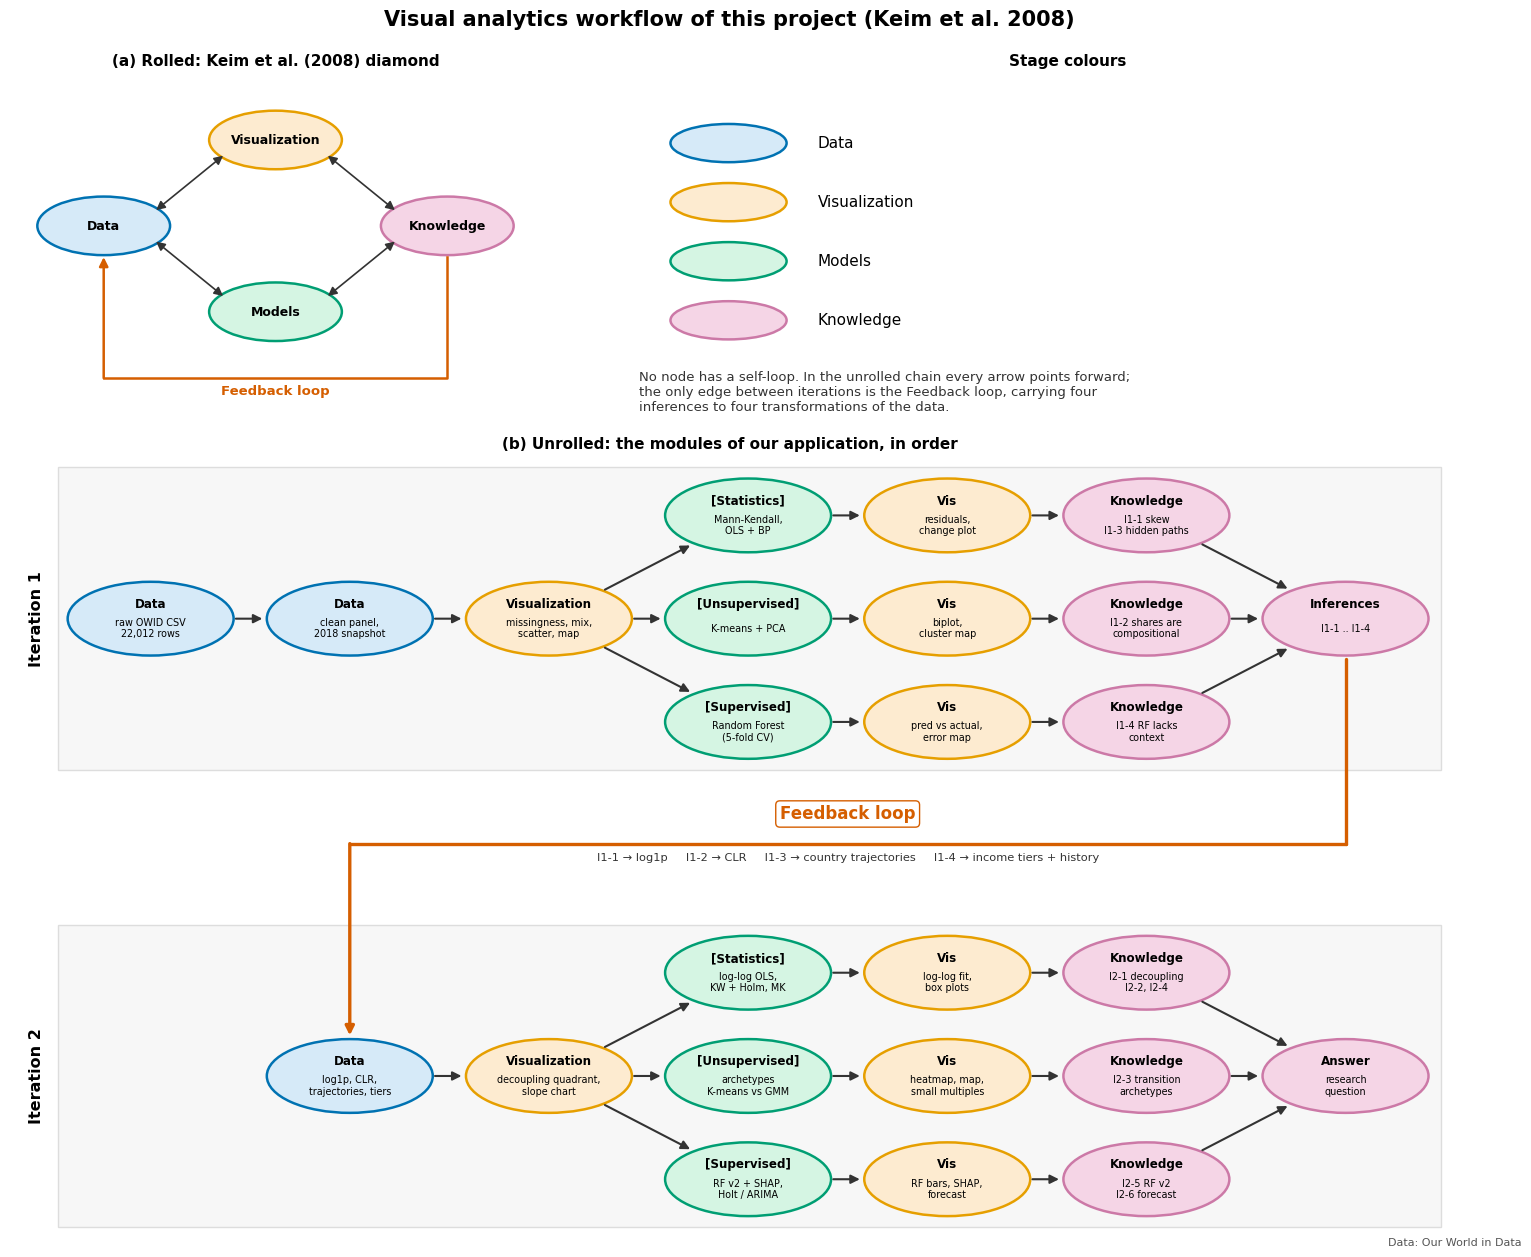

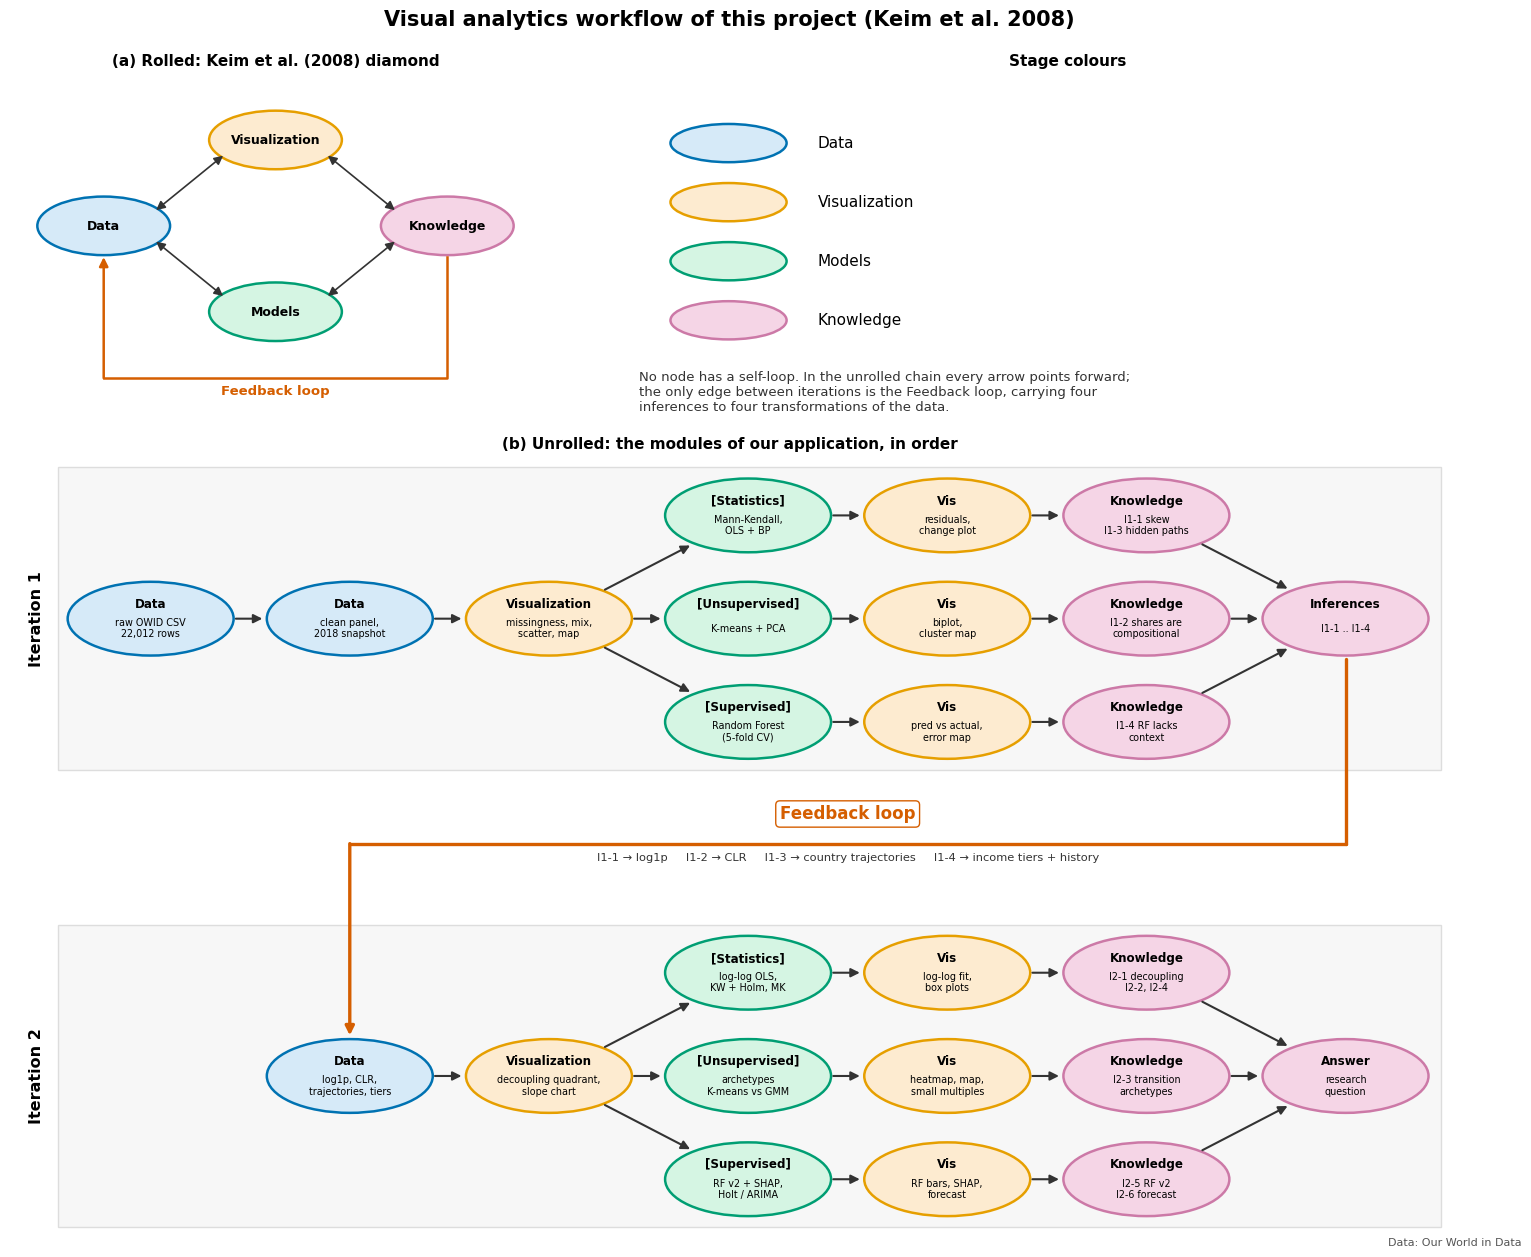

In [91]:
import shutil

from src import workflow_diagram

fig = workflow_diagram.draw()
plots.add_source_note(fig)
fig.savefig(
    config.IMAGES / "workflow.png", dpi=config.FIG_DPI, bbox_inches="tight", facecolor="white"
)
shutil.copyfile(config.IMAGES / "workflow.png", config.REPORT / "workflow.png")  # plan 7.1
plots.register_figure(
    "workflow.png",
    "Phase 5 (report)",
    "(a) The generic Keim et al. diamond, rolled, with its feedback loop back to Data. (b) Our "
    "application unrolled: one oval per module in the order it ran, coloured by diamond stage, "
    "with three lanes per iteration ([Statistics], [Unsupervised], [Supervised]) and a single "
    "forward edge labelled 'Feedback loop' carrying the four inference -> transformation pairs.",
    "Showing the rolled diamond next to its unrolled form makes the feedback loop explicit: the "
    "cycle becomes one labelled forward edge, with no self-loops or back-edges, as the brief asks, "
    "and every model is visibly followed by a visualization and a piece of knowledge.",
    "",
)
fig

## Phase 6: Final audits
Two mechanical checks close the notebook. The **number audit** traces every number in the inference log to a value in the results files the inference cites. The **figure audit** checks that every figure has its file, its registry row, a resolution of at least 150 dpi and a known inference ID, and that every file the plan names exists.

In [92]:
from src import figure_audit, number_audit

number_report = number_audit.run()
ns = number_report["summary"]
print(
    f"Number audit: {ns['numbers_checked']} numbers in {ns['inferences']} inferences; "
    f"untraced: {len(ns['untraced'])}; evidence lines to complete: "
    f"{len(ns['needs_evidence_line_update'])}"
)
assert not ns["untraced"], ns["untraced"]
assert not ns["needs_evidence_line_update"], ns["needs_evidence_line_update"]

figure_report = figure_audit.run()
print(
    f"Figure audit: {figure_report['n_checked']} figures checked "
    f"(file, registry row, dpi, inference ID); ok = {figure_report['ok']}"
)
assert figure_report["ok"], figure_report


Number audit: 203 numbers in 10 inferences; untraced: 0; evidence lines to complete: 0


Figure audit: 32 figures checked (file, registry row, dpi, inference ID); ok = True
